In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# How the budget laws were financed, and what that says about the deficit and the debt
Each year the Italian government proposes a budget law (*manovra*) whose cost must be *covered*. The dossiers "Effetti sui saldi e conto risorse e impieghi" of the Camera and Senate budget services reproduce the government's technical report as a table: **impieghi** (uses: higher spending and lower revenue) against **risorse** (resources: higher revenue and lower spending); the balance is resources minus uses. This notebook measures the coverage of each manovra from 2016 to 2026 and then asks, as an exploratory exercise, whether the planned deficit effect lines up with what happened to the deficit and the debt.

**Data and checks.** 13 dossiers parsed by `sources/budget_laws.py`; every table satisfies the accounting identities (uses = higher spending + lower revenue, resources = higher revenue + lower spending, balance = resources - uses), and 2025 was also checked against the page image. 2018 is the initial bill; 2019 has totals only (no composition); **2022 has no published gross split** (the budget service published no "Effetti sui saldi" dossier for that law): the net figure comes from the summary prospetto of its Nota di lettura 274, and the uses and resources are **rebuilt from the article-by-article measure lines of the same prospetto** (each measure is a use if it raises spending or lowers revenue, a resource otherwise; the Sezione I lines reproduce the net totals and resources minus uses reproduce the net manovra, `evidence` = `reconstructed_from_measure_lines`), so its ratio is comparable with the others but not the government's own table (the result without it is the earlier one: see the takeaways). The 2020-21 pandemic decrees are separate legal acts and are kept apart.

**Measures** (net borrowing, first year of each law unless stated): coverage ratio = resources / uses (1 = fully covered inside the manovra, 0 = entirely financed by deficit); deficit-financed share = 1 - coverage; the deficit effect in % of GDP; the split of the resources into higher revenue and lower spending. Each manovra is attributed to the government in office on 15 October of the previous year (the draft budgetary plan), except the 2023 bill, which the Meloni government presented in November 2022 after taking office on 22 October.

**Link to the outcomes (exploratory).** A manovra can only act on the primary balance, and only by its planned amount, so debt/GDP is the weakest link by construction: nominal growth, interest and stock-flow items (the Superbonus tax credits, for instance) move it more. The pre-specified family has two predictors (planned deficit effect in % of GDP, deficit-financed share) against three outcomes of the same calendar year (change in net borrowing, change in the primary deficit, change in debt/GDP; all in percentage points of GDP, positive = looser), expected sign positive, Spearman with a permutation p, BH over the six tests. Checks: leave-one-year-out, without 2020-21, with the pandemic decrees added, a lead placebo (the previous year's outcomes) and a year-shuffle null that must give about zero discoveries. A second family asks whether the planned effect and the deficit-financed share go with the **deficit surprise** (outturn minus the programmatic deficit target the government gave for that year in its draft budgetary plan, `sources/deficit_targets.py`; two tests). With about ten years, only a rank correlation of about 0.65 or more can be told from zero. One country, no placebo countries: nothing here is a causal claim.

first year of each law (EUR million; shares of the uses; GDP shares of the outturn nominal GDP):


,government,uses,resources,balance,coverage_ratio,deficit_financed_share,uses_pct_gdp,deficit_pct_gdp,resources_from_revenue,resources_from_spending,uses_spending_share
budget_year,,,,,,,,,,,
2016,Renzi,28697.5,14115.9,-14581.7,0.492,0.508,1.686,0.857,0.200,0.292,0.171
2017,Renzi,34473.9,22495.4,-11978.5,0.653,0.347,1.980,0.688,0.304,0.348,0.514
2018,Gentiloni,26427.7,15481.8,-10945.9,0.586,0.414,1.489,0.617,0.403,0.182,0.242
2019,Conte I,43838.0,21990.9,-21847.1,0.502,0.498,2.435,1.214,NaN,NaN,NaN
2020,Conte II,32034.8,15761.3,-16273.5,0.492,0.508,1.923,0.977,0.201,0.291,0.144
2021,Conte II,30941.0,6313.8,-24627.2,0.204,0.796,1.683,1.339,0.098,0.106,0.783
2022,Draghi,36797.5,13539.9,-23258.0,0.368,0.632,1.841,1.164,0.222,0.146,0.698
2023,Meloni,42291.5,21167.7,-21123.8,0.501,0.499,1.975,0.986,0.220,0.281,0.543
2024,Meloni,32801.3,17138.1,-15663.2,0.522,0.478,1.484,0.709,0.260,0.262,0.470


same, summed over the three-year horizon (laws with all three years and a gross split):


,uses,resources,balance,coverage_ratio,deficit_financed_share
budget_year,,,,,
2016,91205.4,41261.1,-49944.4,0.452,0.548
2017,97071.1,75724.6,-21346.5,0.780,0.220
2018,63280.0,37946.7,-25333.3,0.600,0.400
2019,141028.5,67116.2,-73912.3,0.476,0.524
2020,94405.9,54909.2,-39496.7,0.582,0.418
2021,98470.2,65334.4,-33135.7,0.663,0.337
2022,112464.8,33646.2,-78819.2,0.299,0.701
2023,92258.6,73503.7,-18754.9,0.797,0.203
2024,66717.5,50509.0,-16208.5,0.757,0.243


bill plus its decree-law (2020: DL 124/2019, 2024: DL 145/2023), coverage ratio: {2016: 0.492, 2017: 0.653, 2018: 0.586, 2019: 0.502, 2020: 0.566, 2021: 0.204, 2022: 0.368, 2023: 0.501, 2024: 0.57, 2025: 0.745, 2026: 0.958}
pandemic decrees:


,government,uses,resources,balance,coverage_ratio,deficit_pct_gdp
budget_year,,,,,,
2020,Conte II,115381.7,10242.5,-105139.2,0.089,6.311
2021,Draghi,32636.5,1125.1,-31511.4,0.034,1.714


coverage ratio, years 2016-2024 without 2021: {2016: 0.49, 2017: 0.65, 2018: 0.59, 2019: 0.5, 2020: 0.49, 2022: 0.37, 2023: 0.5, 2024: 0.52} | 2025: 0.74 | 2026: 0.96


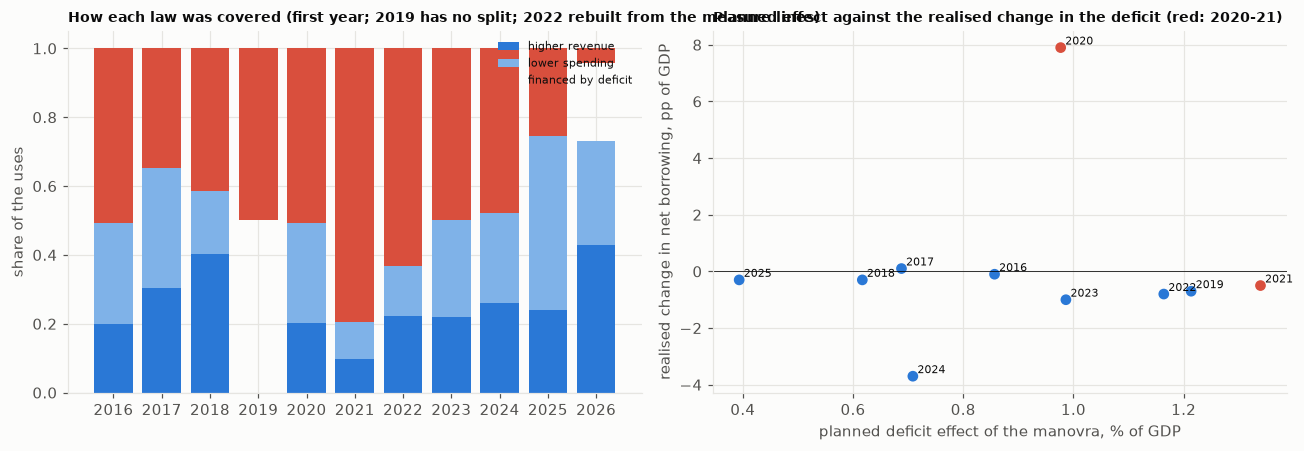

In [2]:
from cifresignificative.studies.italy_productivity.analysis import budget as BU, experiments as ex
bres = ex.run_budget_all()
first, three, T, fam = bres["b1_first_year"], bres["b2_three_year"], bres["b3_link_table"].set_index("budget_year"), bres["b4_family"]
fb = first[first.scope.eq("bill")].set_index("budget_year")
cols = ["government", "uses", "resources", "balance", "coverage_ratio", "deficit_financed_share", "uses_pct_gdp", "deficit_pct_gdp", "resources_from_revenue", "resources_from_spending", "uses_spending_share"]
print("first year of each law (EUR million; shares of the uses; GDP shares of the outturn nominal GDP):"); display(fb[cols].round(3))
print("same, summed over the three-year horizon (laws with all three years and a gross split):"); display(three[three.scope.eq("bill")].set_index("budget_year")[["uses", "resources", "balance", "coverage_ratio", "deficit_financed_share"]].round(3))
bud = first[first.scope.eq("budget")].set_index("budget_year"); print("bill plus its decree-law (2020: DL 124/2019, 2024: DL 145/2023), coverage ratio:", bud.coverage_ratio.round(3).dropna().to_dict())
pan = first[first.scope.eq("pandemic")].set_index("budget_year"); print("pandemic decrees:"); display(pan[["government", "uses", "resources", "balance", "coverage_ratio", "deficit_pct_gdp"]].round(3))
cr = fb.coverage_ratio.dropna()
print("coverage ratio, years 2016-2024 without 2021:", cr.drop(2021)[cr.drop(2021).index <= 2024].round(2).to_dict(), "| 2025:", round(cr[2025], 2), "| 2026:", round(cr[2026], 2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
y = fb; x = np.arange(len(y))
axes[0].bar(x, y.resources_from_revenue.fillna(0), color="#2a78d6", label="higher revenue"); axes[0].bar(x, y.resources_from_spending.fillna(0), bottom=y.resources_from_revenue.fillna(0), color="#7fb2e8", label="lower spending")
axes[0].bar(x, y.deficit_financed_share, bottom=y.coverage_ratio, color="#d94f3d", label="financed by deficit")
axes[0].set_xticks(x); axes[0].set_xticklabels(y.index, rotation=0); axes[0].set_ylabel("share of the uses"); axes[0].set_title("How each law was covered (first year; 2019 has no split; 2022 rebuilt from the measure lines)", fontsize=9); axes[0].legend(fontsize=7)
a = T.loc[2016:2025]
axes[1].scatter(a.deficit_pct_gdp, a.delta_deficit, c=np.where(a.index.isin([2020, 2021]), "#d94f3d", "#2a78d6"))
for t, r in a.iterrows(): axes[1].annotate(str(t), (r.deficit_pct_gdp, r.delta_deficit), fontsize=7, xytext=(3, 2), textcoords="offset points")
axes[1].axhline(0, color="k", lw=.5); axes[1].set_xlabel("planned deficit effect of the manovra, % of GDP"); axes[1].set_ylabel("realised change in net borrowing, pp of GDP"); axes[1].set_title("Planned effect against the realised change in the deficit (red: 2020-21)", fontsize=9)
plt.tight_layout(); plt.show()

In [3]:
dec = bres["b9_debt_decomposition"].set_index("year").loc[2016:2025]
print("realised outcomes by calendar year (pp of GDP; deficit and debt levels in % of GDP) next to the planned deficit effect:")
display(T.loc[2016:2025, ["deficit_pct_gdp", "deficit", "delta_deficit", "delta_primary_deficit", "delta_debt", "real_growth"]].round(2))
print("change in debt/GDP split into primary balance, interest, nominal growth and stock-flow (pp of GDP):"); display(dec[["delta_debt", "debt_primary", "debt_interest", "debt_nominal", "debt_other"]].round(1))
print("realised deficit over the planned deficit effect of the manovra:", (T.loc[2016:2025, "deficit"] / T.loc[2016:2025, "deficit_pct_gdp"]).round(1).to_dict())

realised outcomes by calendar year (pp of GDP; deficit and debt levels in % of GDP) next to the planned deficit effect:


,deficit_pct_gdp,deficit,delta_deficit,delta_primary_deficit,delta_debt,real_growth
budget_year,,,,,,
2016,0.86,2.4,-0.1,0.1,-0.5,1.5
2017,0.69,2.5,0.1,0.2,-0.5,1.7
2018,0.62,2.2,-0.3,-0.1,0.5,1.0
2019,1.21,1.5,-0.7,-0.4,-0.3,0.6
2020,0.98,9.4,7.9,7.8,20.5,-8.7
2021,1.34,8.9,-0.5,-0.5,-8.6,9.2
2022,1.16,8.1,-0.8,-1.5,-7.7,4.9
2023,0.99,7.1,-1.0,-0.5,-4.4,1.0
2024,0.71,3.4,-3.7,-4.0,0.3,1.1


change in debt/GDP split into primary balance, interest, nominal growth and stock-flow (pp of GDP):


,delta_debt,debt_primary,debt_interest,debt_nominal,debt_other
year,,,,,
2016,-0.5,-1.5,3.8,-3.3,0.4
2017,-0.5,-1.3,3.7,-3.0,0.1
2018,0.5,-1.4,3.5,-2.5,0.8
2019,-0.3,-1.8,3.3,-1.9,0.2
2020,20.5,6.5,3.7,10.8,-0.5
2021,-8.6,5.0,3.1,-14.5,-2.1
2022,-7.7,3.7,3.8,-11.7,-3.5
2023,-4.4,3.3,3.4,-9.3,-1.8
2024,0.3,-0.5,3.8,-4.2,1.2


realised deficit over the planned deficit effect of the manovra: {2016: 2.8, 2017: 3.6, 2018: 3.6, 2019: 1.2, 2020: 9.6, 2021: 6.6, 2022: 7.0, 2023: 7.2, 2024: 4.8, 2025: 7.9}


In [4]:
print("pre-specified family, 2016-2025 (rho = Spearman, p = permutation, q = BH over the six tests):"); display(fam[["x", "y", "n", "rho", "p", "q_value", "loo_min", "loo_max", "loo_sign_flips"]].round(3))
print("without 2020-21:"); display(bres["b5_family_ex_covid"][["x", "y", "n", "rho", "p", "q_value"]].round(3))
print("with the pandemic decrees added to 2020 and 2021:"); display(bres["b6_family_with_pandemic"][["x", "y", "n", "rho", "p", "q_value"]].round(3))
print("lead placebo (the manovra of year t against the outcomes of year t-1):"); display(bres["b7_lead_placebo"][["x", "y", "n", "rho", "p", "q_value"]].round(3))
nl = bres["b8_null"]; print("year-shuffle null,", len(nl), "shuffles: mean discoveries", round(float(nl.discoveries.mean()), 3), "| shuffles with a discovery", round(float((nl.discoveries > 0).mean()), 3), "| mean share of p < 0.05", round(float(nl.share_p_below_005.mean()), 3))
print("discoveries in the main family:", int(fam.significant.sum()), "of", len(fam), "| smallest q:", round(float(fam.q_value.min()), 3), "| signs of rho:", (np.sign(fam.rho)).astype(int).tolist())

pre-specified family, 2016-2025 (rho = Spearman, p = permutation, q = BH over the six tests):


,x,y,n,rho,p,q_value,loo_min,loo_max,loo_sign_flips
0,deficit_pct_gdp,delta_deficit,10,-0.340,0.334,0.501,-0.527,-0.259,0
1,deficit_pct_gdp,delta_primary_deficit,10,-0.358,0.316,0.501,-0.550,-0.283,0
2,deficit_pct_gdp,delta_debt,10,-0.638,0.052,0.186,-0.787,-0.502,0
3,deficit_financed_share,delta_deficit,10,-0.140,0.697,0.697,-0.335,0.042,1
4,deficit_financed_share,delta_primary_deficit,10,-0.224,0.536,0.644,-0.417,-0.067,0
5,deficit_financed_share,delta_debt,10,-0.614,0.062,0.186,-0.845,-0.469,0


without 2020-21:


,x,y,n,rho,p,q_value
0,deficit_pct_gdp,delta_deficit,8,-0.419,0.302,0.379
1,deficit_pct_gdp,delta_primary_deficit,8,-0.429,0.299,0.379
2,deficit_pct_gdp,delta_debt,8,-0.695,0.063,0.190
3,deficit_financed_share,delta_deficit,8,-0.359,0.379,0.379
4,deficit_financed_share,delta_primary_deficit,8,-0.381,0.361,0.379
5,deficit_financed_share,delta_debt,8,-0.778,0.028,0.168


with the pandemic decrees added to 2020 and 2021:


,x,y,n,rho,p,q_value
0,deficit_pct_gdp,delta_deficit,10,-0.024,0.955,0.955
1,deficit_pct_gdp,delta_primary_deficit,10,-0.042,0.919,0.955
2,deficit_pct_gdp,delta_debt,10,-0.298,0.402,0.955
3,deficit_financed_share,delta_deficit,10,-0.030,0.938,0.955
4,deficit_financed_share,delta_primary_deficit,10,-0.103,0.783,0.955
5,deficit_financed_share,delta_debt,10,-0.450,0.191,0.955


lead placebo (the manovra of year t against the outcomes of year t-1):


,x,y,n,rho,p,q_value
0,deficit_pct_gdp,delta_deficit,10,0.298,0.396,0.722
1,deficit_pct_gdp,delta_primary_deficit,10,0.255,0.481,0.722
2,deficit_pct_gdp,delta_debt,10,0.170,0.640,0.768
3,deficit_financed_share,delta_deficit,10,0.304,0.387,0.722
4,deficit_financed_share,delta_primary_deficit,10,0.377,0.278,0.722
5,deficit_financed_share,delta_debt,10,0.049,0.901,0.901


year-shuffle null, 300 shuffles: mean discoveries 0.087 | shuffles with a discovery 0.063 | mean share of p < 0.05 0.059
discoveries in the main family: 0 of 6 | smallest q: 0.186 | signs of rho: [-1, -1, -1, -1, -1, -1]


programmatic deficit target of the budget year (draft budgetary plan or dossier), the outturn and the miss (pp of GDP, positive deficits; surprise = outturn - target, positive = a larger deficit than planned):


,government,deficit_pct_gdp,target,target_final,deficit,deficit_surprise,deficit_surprise_final,planned_delta_deficit,delta_deficit
budget_year,,,,,,,,,
2016,Renzi,0.86,2.2,2.20,2.4,0.2,0.20,-0.3,-0.1
2017,Renzi,0.69,2.3,2.30,2.5,0.2,0.20,-0.1,0.1
2018,Gentiloni,0.62,1.6,1.60,2.2,0.6,0.60,-0.9,-0.3
2019,Conte I,1.21,2.4,2.04,1.5,-0.9,-0.54,0.2,-0.7
2020,Conte II,0.98,2.2,2.20,9.4,7.2,7.20,0.7,7.9
2021,Conte II,1.34,7.0,7.00,8.9,1.9,1.90,-2.4,-0.5
2022,Draghi,1.16,5.6,5.60,8.1,2.5,2.50,-3.3,-0.8
2023,Meloni,0.99,4.5,4.50,7.1,2.6,2.60,-3.6,-1.0
2024,Meloni,0.71,4.3,4.30,3.4,-0.9,-0.90,-2.8,-3.7


second pre-specified family: the manovra against the deficit surprise (BH over the two tests):


,x,y,n,rho,p,q_value,loo_min,loo_max
0,deficit_pct_gdp,deficit_surprise,10,0.292,0.411,0.411,0.176,0.633
1,deficit_financed_share,deficit_surprise,10,0.486,0.159,0.318,0.410,0.594


without 2020-21:


,x,y,n,rho,p,q_value
0,deficit_pct_gdp,deficit_surprise,8,0.072,0.872,0.872
1,deficit_financed_share,deficit_surprise,8,0.347,0.395,0.791


against the revised target (2019: 2.04 instead of 2.4):


,x,y,n,rho,p,q_value
0,deficit_pct_gdp,deficit_surprise,10,0.321,0.370,0.370
1,deficit_financed_share,deficit_surprise,10,0.491,0.157,0.315


year-shuffle null of this family: 300 shuffles, mean discoveries 0.077 | shuffles with a discovery 0.05
how well the target anticipated the change in the deficit (change implied by the plan = target - last year's outturn, against the realised change):


,years,n,rho,p,same_sign
0,all years,10,0.747,0.014,8
1,without 2020-21,8,0.620,0.107,6


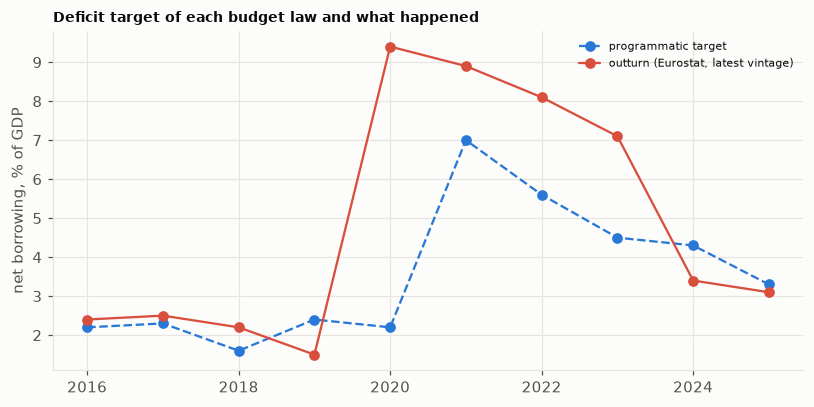

In [5]:
tg = BU.targets()
print("programmatic deficit target of the budget year (draft budgetary plan or dossier), the outturn and the miss (pp of GDP, positive deficits; surprise = outturn - target, positive = a larger deficit than planned):")
display(T.loc[2016:2025, ["government", "deficit_pct_gdp", "target", "target_final", "deficit", "deficit_surprise", "deficit_surprise_final", "planned_delta_deficit", "delta_deficit"]].round(2))
print("second pre-specified family: the manovra against the deficit surprise (BH over the two tests):"); display(bres["b10_surprise_family"][["x", "y", "n", "rho", "p", "q_value", "loo_min", "loo_max"]].round(3))
print("without 2020-21:"); display(bres["b11_surprise_ex_covid"][["x", "y", "n", "rho", "p", "q_value"]].round(3))
print("against the revised target (2019: 2.04 instead of 2.4):"); display(bres["b12_surprise_final_target"][["x", "y", "n", "rho", "p", "q_value"]].round(3))
n2 = bres["b13_surprise_null"]; print("year-shuffle null of this family:", len(n2), "shuffles, mean discoveries", round(float(n2.discoveries.mean()), 3), "| shuffles with a discovery", round(float((n2.discoveries > 0).mean()), 3))
print("how well the target anticipated the change in the deficit (change implied by the plan = target - last year's outturn, against the realised change):"); display(bres["b14_plan_vs_outturn"].round(3))
fig, ax = plt.subplots(figsize=(7.5, 3.8)); a = T.loc[2016:2025]
ax.plot(a.index, a.target, "o--", color="#2a78d6", label="programmatic target"); ax.plot(a.index, a.deficit, "o-", color="#d94f3d", label="outturn (Eurostat, latest vintage)")
ax.set_ylabel("net borrowing, % of GDP"); ax.set_title("Deficit target of each budget law and what happened", fontsize=9); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

deficit surprise split into revenue shortfall, primary-expenditure overrun, interest overrun (EUR levels in % of the outturn GDP; revenue shortfall negative = revenue above plan) and a denominator effect; gdp_ratio = forecast / outturn nominal GDP:


,deficit_surprise,revenue_shortfall,primary_expenditure_overrun,interest_overrun,denominator_effect,rounding,gdp_ratio
budget_year,,,,,,,
2016,0.2,0.21,0.26,-0.24,-0.03,-0.0,0.99
2017,0.2,-0.66,0.73,0.18,-0.05,-0.0,0.98
2018,0.6,0.06,0.54,0.01,-0.00,0.0,1.00
2019,-0.9,-0.72,0.14,-0.45,0.03,0.1,1.01
2020,7.2,3.26,3.94,-0.20,0.20,0.0,1.09
2021,1.9,-1.68,3.54,0.24,-0.31,0.1,0.96
2022,2.5,-2.18,3.72,1.35,-0.29,-0.1,0.95
2023,2.6,-0.68,3.81,-0.22,-0.31,-0.0,0.93
2024,-0.9,-2.11,1.52,-0.15,-0.15,0.0,0.97


growth forecast errors (outturn minus the plan's forecast, pp):


,real_growth_forecast,real_growth,real_growth_error,nominal_growth_forecast,nominal_growth,nominal_growth_error
budget_year,,,,,,
2016,1.6,1.5,-0.1,2.6,2.5,-0.1
2017,1.0,1.7,0.7,2.0,2.3,0.3
2018,1.5,1.0,-0.5,3.1,1.9,-1.2
2019,1.5,0.6,-0.9,3.1,1.5,-1.6
2020,0.6,-8.7,-9.3,2.0,-7.5,-9.5
2021,6.0,9.2,3.2,6.8,10.4,3.6
2022,4.7,4.9,0.2,6.4,8.7,2.3
2023,0.6,1.0,0.4,4.8,7.2,2.4
2024,1.2,1.1,-0.1,4.1,3.2,-0.9


rank correlations with the nominal and real growth errors (permutation p):


,years,x,y,n,rho,p
0,all years,deficit_surprise,real_growth_error,10,0.188,0.598
1,all years,deficit_surprise,nominal_growth_error,10,0.286,0.420
2,all years,revenue_shortfall,nominal_growth_error,10,-0.430,0.224
3,all years,primary_expenditure_overrun,nominal_growth_error,10,0.273,0.452
4,all years,interest_overrun,nominal_growth_error,10,0.479,0.162
5,all years,denominator_effect,nominal_growth_error,10,-0.903,0.001
6,without 2020-21,deficit_surprise,real_growth_error,8,0.599,0.123
7,without 2020-21,deficit_surprise,nominal_growth_error,8,0.743,0.043
8,without 2020-21,revenue_shortfall,nominal_growth_error,8,-0.071,0.878
9,without 2020-21,primary_expenditure_overrun,nominal_growth_error,8,0.714,0.060


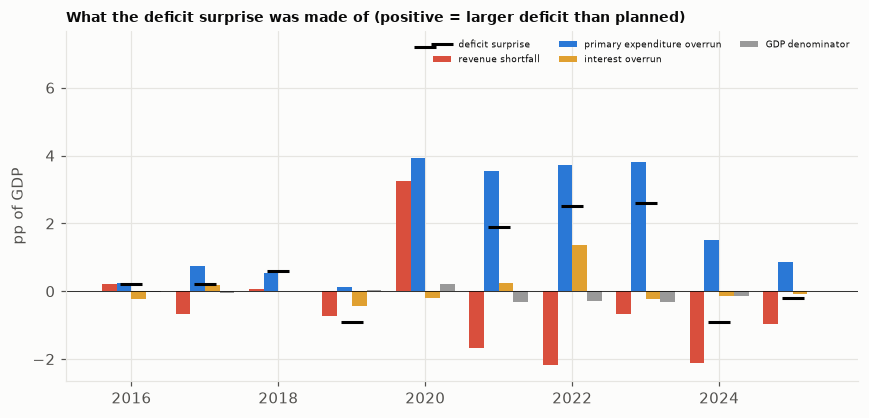

In [6]:
dec = bres["b15_surprise_decomposition"].set_index("budget_year")
print("deficit surprise split into revenue shortfall, primary-expenditure overrun, interest overrun (EUR levels in % of the outturn GDP; revenue shortfall negative = revenue above plan) and a denominator effect; gdp_ratio = forecast / outturn nominal GDP:")
display(dec[["deficit_surprise", "revenue_shortfall", "primary_expenditure_overrun", "interest_overrun", "denominator_effect", "rounding", "gdp_ratio"]].round(2))
print("growth forecast errors (outturn minus the plan's forecast, pp):"); display(dec[["real_growth_forecast", "real_growth", "real_growth_error", "nominal_growth_forecast", "nominal_growth", "nominal_growth_error"]].round(1))
print("rank correlations with the nominal and real growth errors (permutation p):"); display(bres["b16_surprise_drivers"].round(3))
fig, ax = plt.subplots(figsize=(8, 3.9)); yrs = dec.index.to_numpy(); w = 0.2
for k, (c, lab, col) in enumerate([("revenue_shortfall", "revenue shortfall", "#d94f3d"), ("primary_expenditure_overrun", "primary expenditure overrun", "#2a78d6"), ("interest_overrun", "interest overrun", "#e0a030"), ("denominator_effect", "GDP denominator", "#999999")]):
    ax.bar(yrs + (k - 1.5) * w, dec[c], width=w, color=col, label=lab)
ax.plot(yrs, dec.deficit_surprise, "k_", ms=14, mew=2, label="deficit surprise"); ax.axhline(0, color="k", lw=.5); ax.set_ylabel("pp of GDP"); ax.set_title("What the deficit surprise was made of (positive = larger deficit than planned)", fontsize=9); ax.legend(fontsize=6, ncol=3); plt.tight_layout(); plt.show()

### Which expenditure categories drove the overruns
The plan's target table splits total expenditure into eight rows (compensation of employees D.1, intermediate consumption P.2, social payments D.62/D.632, interest D.41, subsidies D.3, gross fixed capital formation P.51, capital transfers D.9 and a residual); Eurostat (`gov_10a_main`) has the outturn for the same categories. The miss of each category is computed as above (euro-level, in % of the outturn GDP, positive = more spending than planned) and the eight sum to the miss of total expenditure up to rounding. This attributes the overruns to *categories*, not to individual measures: a category mixes many measures, and the 2016 plan classified some items differently from later plans (intermediate consumption and social payments), so the 2016 split is not comparable.

expenditure miss by category (outturn minus target, euro-level, % of outturn GDP; positive = more spending than planned):


,compensation of employees,intermediate consumption,social payments,interest,subsidies,gross fixed capital formation,capital transfers,other,total,total_expenditure_miss
budget_year,,,,,,,,,,
2016,0.04,-1.79,2.29,-0.24,0.32,0.03,-0.48,-0.07,0.12,0.02
2017,0.20,0.41,-0.23,0.18,0.13,-0.15,0.42,-0.05,0.91,0.91
2018,0.23,0.42,-0.23,0.01,0.10,0.11,-0.10,0.01,0.55,0.55
2019,0.08,0.13,-0.59,-0.45,0.28,0.27,-0.22,0.07,-0.41,-0.31
2020,0.02,0.09,1.26,-0.20,0.57,0.08,1.51,0.30,3.63,3.73
2021,-0.14,0.17,0.00,0.24,0.28,-0.35,3.37,0.21,3.79,3.79
2022,-0.37,0.41,0.07,1.35,0.59,-0.24,3.11,0.14,5.07,5.07
2023,0.05,0.01,0.04,-0.22,-0.90,0.13,4.22,0.26,3.59,3.59
2024,0.21,0.20,0.01,-0.15,-0.04,0.51,0.45,0.07,1.27,1.36


largest category each year: {2020: 'capital transfers (1.51)', 2021: 'capital transfers (3.37)', 2022: 'capital transfers (3.11)', 2023: 'capital transfers (4.22)'}
capital transfers in 2021-2023: {2021: 3.37, 2022: 3.11, 2023: 4.22} | share of the total expenditure miss: {2021: 0.89, 2022: 0.61, 2023: 1.18}
max |sum of categories - miss of total expenditure|: 0.109


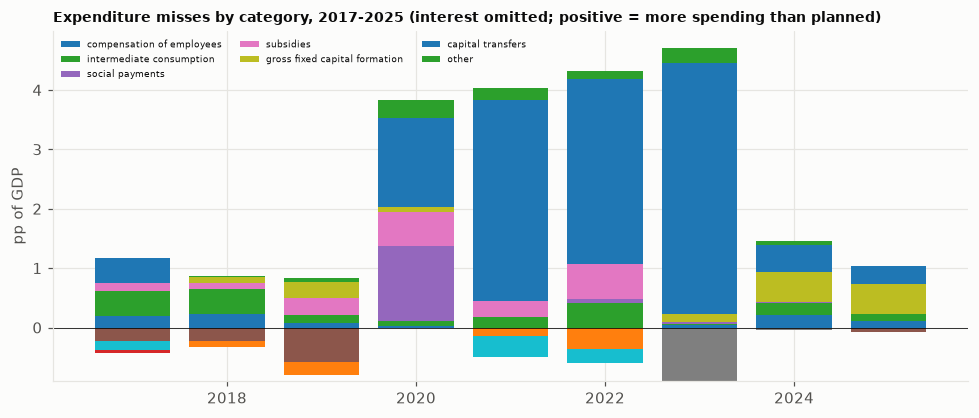

In [7]:
cat = bres["b17_expenditure_by_category"].set_index("budget_year")
print("expenditure miss by category (outturn minus target, euro-level, % of outturn GDP; positive = more spending than planned):"); display(cat.round(2))
big = cat.drop(columns=["total", "total_expenditure_miss"]).loc[2020:2023]
print("largest category each year:", {int(t): f"{r.idxmax()} ({r.max():.2f})" for t, r in big.iterrows()})
print("capital transfers in 2021-2023:", cat.loc[2021:2023, "capital transfers"].round(2).to_dict(), "| share of the total expenditure miss:", (cat.loc[2021:2023, "capital transfers"] / cat.loc[2021:2023, "total"]).round(2).to_dict())
print("max |sum of categories - miss of total expenditure|:", round(float((cat.total - cat.total_expenditure_miss).abs().max()), 3))
fig, ax = plt.subplots(figsize=(9, 3.9)); cc = cat.drop(columns=["total", "total_expenditure_miss", "interest"]).loc[2017:2025]; bottom_pos = np.zeros(len(cc)); bottom_neg = np.zeros(len(cc))
for c in cc.columns:
    v = cc[c].to_numpy(); ax.bar(cc.index, np.where(v > 0, v, 0), bottom=bottom_pos, label=c); ax.bar(cc.index, np.where(v < 0, v, 0), bottom=bottom_neg); bottom_pos += np.where(v > 0, v, 0); bottom_neg += np.where(v < 0, v, 0)
ax.axhline(0, color="k", lw=.5); ax.set_ylabel("pp of GDP"); ax.set_title("Expenditure misses by category, 2017-2025 (interest omitted; positive = more spending than planned)", fontsize=9); ax.legend(fontsize=6, ncol=3); plt.tight_layout(); plt.show()

### The building credits inside the capital-transfer overruns: an ENEA lower bound and Istat's own figures
The capital-transfer overruns of 2021-23 are consistent with the Eurostat decision under which the Superbonus and building-bonus credits are capital expenditure when the works are done, but the category also holds other grants. ENEA's monthly bulletins give the Superbonus (110%) investments for completed works and the deductions (tax credits) accrued each December, cumulative (`data/external/enea_superbonus.csv`, transcribed from ENEA's annual reports with report and table; `analysis/superbonus.py`). Yearly flows are the differences between December snapshots (2021 is the cumulative since July 2020). Compared in euro with the capital-transfer overrun (pp of GDP times the outturn GDP). **This is a lower bound, not the amount:** ENEA covers the Superbonus only (no facade bonus, ordinary ecobonus, sismabonus or other building bonuses); the overrun is against the plan, which may already hold part of the credits; snapshots are by transmission date, so late transmissions move works between years (the flow of one year is understated, the next overstated). **Istat's own figures.** For the whole Superbonus (super ecobonus and super sismabonus) Istat gave the Senate budget committee on 26 April 2024 the effect on net borrowing as 0.03, 0.9, 2.8 and 3.9% of GDP in 2020-23, over 150 billion euro in total and over 175 billion with the facade bonus (about 23 billion for 2020-22 by difference); the numbers were first taken from the Camera's Dossier OFP n. 4 and then **checked against the note itself** (page 6 and footnote 7; the PDF is kept in `data/external/source/istat_note/`; `data/external/istat_superbonus_deficit.csv`). The note adds that only 3.6% of these credits could be used in deduction (the rest is invoice discount or cession) and, quoting the MEF, that the credits of the first cessioni reached 160.5 billion euro by 2023 (before cancellations and seizures). In euro they are the percentage times the outturn GDP, so they can differ by rounding from the dossier's own euro figures. Two further **primary** checks were added: Istat's hearing of March 2023 at the Senate finance committee (the vintage in which the credits were first booked in full, with a chart of the spending for the Superbonus and facade bonus together, read from the bars, about +-0.5 billion) and the Bank of Italy's memorandum of 22 April 2024 (credits matured of about 1%, almost 3% and 3.7% of GDP in 2021-23, almost 8% together).

In [8]:
fl = bres["b18_superbonus_flows"].set_index("budget_year"); lb = bres["b19_superbonus_lower_bound"].set_index("budget_year")
print("ENEA Superbonus flows by year (EUR billion): investments admitted, investments for completed works, deductions (credits) accrued, credit rate:"); display((fl[["investments_admitted_eur", "investments_completed_eur", "deductions_accrued_eur"]] / 1e9).join(fl.credit_rate).round(2))
print("against the capital-transfer overrun (EUR million; shares of the overrun):"); display(lb[["capital_transfers_miss_pct_gdp", "capital_transfers_miss_meur", "superbonus_credits_meur", "credits_pct_gdp", "share_of_capital_transfers_miss", "share_investment_only", "share_of_expenditure_miss", "remainder_meur"]].round(3))
ib = bres["b20_superbonus_istat"].set_index("budget_year")
print("Istat's own Superbonus effect on net borrowing (April 2024 note, as quoted by the Camera dossier), in euro, against the same overrun and against the ENEA credits:"); display(ib.round(3))
vt = bres["b21_superbonus_vintages"].set_index("budget_year")
print("alternative sources and vintages side by side (EUR million; the columns are not parts of one sum): ENEA credits, Istat April 2024 (Superbonus), Istat March 2023 (Superbonus + facade, read from a chart, 2021-22), Bank of Italy credits matured (% of GDP x GDP), Istat March 2023 spending on all firms' tax credits (context):"); display(vt.round(3))
ca = bres["b22_credit_attribution"].set_index("budget_year")
print("2021 and 2022 (Istat March 2023 vintage): overrun minus the building bonuses, then minus the firms' investment-type tax credits (core = Transizione 4.0 + Investimenti Mezzogiorno; wide adds R&D, DTA, vehicle bonus; Tavola 1 shares of the firm credit total), and the subsidy-type credits against the subsidies overrun (EUR million):"); display(ca.round(3))
sp = bres["b23_capital_transfer_split"].set_index("year")
print("Italy's capital transfers split into investment grants (D.92: Superbonus, facade bonus, firms' investment credits, PNRR investment grants) and other capital transfers (D.99: cash grants such as the pandemic contributi a fondo perduto), % of GDP and EUR million, with the change since 2019:"); display(sp[["d92_pct_gdp", "d99_pct_gdp", "d92_meur", "d99_meur", "d92_change_since_2019_meur", "d99_change_since_2019_meur", "building_plus_core_credits_meur", "building_plus_wide_credits_meur", "unexplained_core_meur", "unexplained_wide_meur"]].round(1))
gc = bres["b24_grants_check"].set_index("item").value
print("the 2021 cash grants of the Sostegni decrees (authorized in the technical reports; data/external/covid_grants_2021.csv) against the other capital transfers (D.99) and the unexplained part:"); display(gc.round(3).to_frame("value"))
print("grants at the payment rate of the automatic DL 73 tranche (paid over authorized in the law as converted):", round(float(gc.automatic_paid_over_authorized), 3), "->", round(float(gc.grants_at_payment_rate_meur)), "million; D.99 other than base and grants:", round(float(gc.d99_other_meur)), "million authorized, ", round(float(gc.d99_other_at_payment_rate_meur)), "million at the payment rate")
print("share of the overrun inside the capital-transfer category, 2021-23 together:", round(float(lb.loc["2021-23", "share_of_capital_transfers_miss"]), 3), "| credits", round(float(lb.loc["2021-23", "superbonus_credits_meur"]) / 1000, 1), "bn against an overrun of", round(float(lb.loc["2021-23", "capital_transfers_miss_meur"]) / 1000, 1), "bn")

ENEA Superbonus flows by year (EUR billion): investments admitted, investments for completed works, deductions (credits) accrued, credit rate:


,investments_admitted_eur,investments_completed_eur,deductions_accrued_eur,credit_rate
budget_year,,,,
2021,15.20,10.66,11.72,1.10
2022,45.56,34.55,38.00,1.10
2023,41.92,45.84,50.01,1.09


against the capital-transfer overrun (EUR million; shares of the overrun):


,capital_transfers_miss_pct_gdp,capital_transfers_miss_meur,superbonus_credits_meur,credits_pct_gdp,share_of_capital_transfers_miss,share_investment_only,share_of_expenditure_miss,remainder_meur
budget_year,,,,,,,,
2021,3.374,62038.665,11724.785,0.638,0.189,0.172,0.168,50313.880
2022,3.111,62156.188,37995.191,1.901,0.611,0.556,0.375,24160.997
2023,4.224,90461.368,50012.165,2.335,0.553,0.507,0.650,40449.203
2021-23,NaN,214656.221,99732.140,NaN,0.465,NaN,NaN,114924.081


Istat's own Superbonus effect on net borrowing (April 2024 note, as quoted by the Camera dossier), in euro, against the same overrun and against the ENEA credits:


,istat_superbonus_pct_gdp,istat_superbonus_meur,capital_transfers_miss_meur,share_of_capital_transfers_miss,enea_credits_meur,enea_over_istat,facade_bonus_meur,share_superbonus,share_superbonus_and_facade
budget_year,,,,,,,,,
2021,0.9,16548.073,62038.665,0.267,11724.785,0.709,NaN,NaN,NaN
2022,2.8,55951.535,62156.188,0.900,37995.191,0.679,NaN,NaN,NaN
2023,3.9,83528.671,90461.368,0.923,50012.165,0.599,NaN,NaN,NaN
2021-23,NaN,156028.279,214656.221,NaN,99732.140,0.639,23000.0,0.727,0.834


... (5 outputs left out)

item,d92_pct_gdp,d99_pct_gdp,d92_meur,d99_meur,d92_change_since_2019_meur,d99_change_since_2019_meur,building_plus_core_credits_meur,building_plus_wide_credits_meur,unexplained_core_meur,unexplained_wide_meur
year,,,,,,,,,,
2018,0.7,0.3,12421.2,5323.4,-1981.1,-77.5,NaN,NaN,NaN,NaN
2019,0.8,0.3,14402.3,5400.8,0.0,0.0,NaN,NaN,NaN,NaN
2020,1.1,1.5,18325.8,24989.7,3923.5,19588.8,NaN,NaN,NaN,NaN
2021,3.2,1.8,58837.6,33096.1,44435.3,27695.3,42831.2,49448.8,19207.5,12589.9
2022,4.5,0.6,89922.1,11989.6,75519.9,6588.8,62787.6,66284.1,-631.4,-4127.9
2023,5.5,0.4,117796.8,8567.0,103394.6,3166.2,NaN,NaN,NaN,NaN
2024,1.4,0.3,30948.3,6631.8,16546.1,1230.9,NaN,NaN,NaN,NaN


the 2021 cash grants of the Sostegni decrees (authorized in the technical reports; data/external/covid_grants_2021.csv) against the other capital transfers (D.99) and the unexplained part:


,value
item,
d99_meur,33096.146
d99_base_meur,5400.845
d99_change_meur,27695.301
grants_authorized_net_meur,21725.100
automatic_paid_over_authorized,0.887
grants_at_payment_rate_meur,19273.674
d99_other_meur,5970.201
d99_other_at_payment_rate_meur,8421.627
unexplained_core_meur,19207.465


grants at the payment rate of the automatic DL 73 tranche (paid over authorized in the law as converted): 0.887 -> 19274 million; D.99 other than base and grants: 5970 million authorized,  8422 million at the payment rate
share of the overrun inside the capital-transfer category, 2021-23 together: 0.465 | credits 99.7 bn against an overrun of 214.7 bn


### Istat's own accounts by receiving sector (esploradati)
The previous sections used a judgment-based grouping of firms' credits and Eurostat's total for capital transfers. Istat's annual account of the general government (esploradati SDMX, dataflow `95_815_DF_DCCN_FPA_1` and `5_815_DF_DCCN_FPA_B19_1`; `sources/istat_fpa.py`, committed table `data/external/istat_fpa_s13.csv`, every edition from 2019 to October 2026) gives investment grants (D.92) and other capital transfers (D.99) **by the sector that receives them** (households, corporations, non-profit institutions, rest of the world), and keeps each publication (edition) so that the March 2023 reclassification can be seen directly. Receivers are Istat's classification; flows are accrual.

In [9]:
rc = bres["b25_fpa_receivers"].set_index("year"); ri = bres["b26_fpa_increase"].set_index("year")
print("Istat, edition 2026M10: capital transfers paid by the general government by receiving sector (EUR million):"); display(rc.loc[2015:2025, ["d92_households", "d92_corporations", "d99_corporations", "d99_households", "d92_total", "d99_total", "subsidies"]].round(0))
print("rise over 2019 (EUR million) and, for 2021, the share of the total rise of D.92 + D.99:"); display(ri.loc[2020:2024, ["d92_households", "d92_corporations", "d99_corporations", "d99_households", "d92_total", "d99_total"]].round(0))
tot21 = float(ri.loc[2021, "d92_total"] + ri.loc[2021, "d99_total"]); print("2021 shares of the rise:", {k: round(float(ri.loc[2021, k]) / tot21, 3) for k in ("d92_households", "d92_corporations", "d99_corporations")}, "| rise", round(tot21))
rcl = bres["b27_fpa_reclassification"]; print("the March 2023 reclassification: the same year in the edition of October 2022 and in that of March 2023:"); display(rcl.round(0))
print("Istat's hearing of March 2023 (chart, Superbonus + facade) against the households' investment grants of the March 2023 edition above their 2019 level:"); display(bres["b28_fpa_hearing_check"].round(0))
fs = bres["b29_fpa_facade_split"]; print("Italy's deficit in successive Istat editions (% of the latest nominal GDP, so that only the vintage of the numerator changes) and its surprise against the programmatic target:"); display(bres["b31_fpa_deficit_vintages"].round(2))
sv = bres["b32_surprise_vintages"].set_index("budget_year")
print("deficit surprise and its parts with Istat's FIRST release of each year (the first edition that contains it) and with the latest edition (pp of the latest GDP; revision = latest minus first):"); display(sv[["first_edition", "deficit_surprise_first", "deficit_surprise_latest", "deficit_surprise_revision", "revenue_shortfall_first", "revenue_shortfall_latest", "primary_expenditure_overrun_first", "primary_expenditure_overrun_latest", "primary_expenditure_overrun_revision"]].round(2))
qp = bres["b33_quarterly_capital_profile"]; qr = bres["b34_quarterly_reclassification"]
print("quarterly account (raw series, edition 2026M10): other capital expenditure (D.92 + D.99), net lending and gross fixed capital formation by quarter, EUR million; share of the year:"); display(qp[["period", "other_capital_expenditure", "ooke_share_of_year", "net_lending", "gross_fixed_capital_formation"]].round(2))
print("how the March 2023 booking was spread over the quarters (quarterly edition of April 2023 minus that of January 2023), EUR million:"); display(qr.pivot(index="period", columns="item", values="change").round(0))
rz = bres["b36_superbonus_zones"]; rt = bres["b37_superbonus_rank_tests"]; rr = bres["b35_superbonus_regions"]
print("cross-check: Istat's latest edition against the Eurostat figures used for Italy (gap = Istat minus Eurostat, points of GDP, 2005-2024):"); display(bres["b38_istat_eurostat_check"].round(3))
print("who received the Superbonus: ENEA investments for completed works by zone (shares against population shares), snapshots end 2023 and end 2025:"); display(rz.round(3))
print("investment per inhabitant against GDP per inhabitant (Spearman over 20 regions, permutation p) and the condominium share:"); display(rt.round(3))
print("end-2023 snapshot by region, per inhabitant (EUR):"); display(rr[rr.snapshot.eq("2023-12-31")].sort_values("per_inhabitant_eur", ascending=False)[["region", "zone", "investment_meur", "per_inhabitant_eur", "gdp_per_inhabitant_eur", "condominium_share"]].round(2))
print("implied annual split of the households' investment grants above 2019 into the Superbonus (Istat note of 26 April 2024) and the facade bonus (rest); sum of the implied facade bonus 2020-22:", round(float(fs[fs.year <= 2022].implied_facade_meur.sum())), "million"); display(fs.round(0))

Istat, edition 2026M10: capital transfers paid by the general government by receiving sector (EUR million):


,d92_households,d92_corporations,d99_corporations,d99_households,d92_total,d99_total,subsidies
year,,,,,,,
2015,1331,8689,12656,2200,11133,15021,28657
2016,856,7616,5618,1,9511,6473,30363
2017,891,7874,15995,800,10046,17713,28609
2018,1575,10519,5366,16,13190,5487,30063
2019,1137,11714,4633,12,14021,4669,29881
2020,3087,14094,23664,27,18550,24609,34361
2021,38024,19279,31613,742,58668,33247,37192
2022,56992,31124,10242,318,89955,11302,46065
2023,85241,31980,7735,336,118798,8417,38785


rise over 2019 (EUR million) and, for 2021, the share of the total rise of D.92 + D.99:


,d92_households,d92_corporations,d99_corporations,d99_households,d92_total,d99_total
year,,,,,,
2020,1950,2380,19031,15,4529,19940
2021,36887,7565,26980,730,44647,28578
2022,55855,19410,5609,306,75934,6633
2023,84104,20266,3102,324,104777,3748
2024,6011,10917,2123,1,17682,2347


2021 shares of the rise: {'d92_households': 0.504, 'd92_corporations': 0.103, 'd99_corporations': 0.368} | rise 73225
the March 2023 reclassification: the same year in the edition of October 2022 and in that of March 2023:


,item,year,before,after,change
0,D92_D_W0_S14,2020,1480,3350,1870
1,D92_D_W0_S14,2021,2262,37891,35629
2,D92_D_W0_SIM,2020,13557,14129,572
3,D92_D_W0_SIM,2021,18579,19461,882
4,D99_D_W0_SIM,2020,26749,27157,408
5,D99_D_W0_SIM,2021,32630,33195,565
6,D3_D_W0,2020,32711,32660,-51
7,D3_D_W0,2021,35684,34779,-905
8,B9_B_W0,2020,-157645,-160383,-2738
9,B9_B_W0,2021,-128902,-161210,-32308


... (16 outputs left out)

end-2023 snapshot by region, per inhabitant (EUR):


,region,zone,investment_meur,per_inhabitant_eur,gdp_per_inhabitant_eur,condominium_share
18,Valle d'Aosta,North,436.69,3519.19,38587.95,0.87
16,Trentino-Alto Adige,North,2651.62,2461.87,44527.33,0.79
1,Basilicata,South and Islands,1270.91,2331.38,23788.05,0.70
0,Abruzzo,South and Islands,2963.18,2313.15,26242.28,0.67
4,Emilia-Romagna,North,9464.26,2132.10,38068.48,0.69
19,Veneto,North,9363.48,1922.75,34901.79,0.47
17,Umbria,Centre,1638.54,1893.28,26603.24,0.61
10,Molise,South and Islands,543.72,1847.54,23269.35,0.59
5,Friuli-Venezia Giulia,North,2206.53,1836.46,33703.40,0.54
8,Lombardia,North,17903.74,1793.68,42455.25,0.67


implied annual split of the households' investment grants above 2019 into the Superbonus (Istat note of 26 April 2024) and the facade bonus (rest); sum of the implied facade bonus 2020-22: 21693 million


,year,households_d92_above_base_meur,superbonus_istat_meur,implied_facade_meur
0,2020,1950,500.0,1450.0
1,2021,36887,16548.0,20339.0
2,2022,55855,55952.0,-97.0
3,2023,84104,83529.0,575.0


### Who used the Superbonus, and when: the ENEA monthly reports by region
The annual reports give only two regional snapshots. ENEA also publishes a monthly report (62 month ends, August 2021 to September 2026; 22 pages each: Italy, the 20 regions, a summary), and `sources/enea_monthly.py` parses all of them into `data/external/enea_superbonus_monthly.csv` (admitted investment, investment of the completed works, deductions accrued, and the same by type of building; cumulative since July 2020, by transmission date, SuperEcobonus only). Checks: in every month the 20 regions add up to Italy (largest gap 56 thousand euro, March 2023) and the national totals match the transcribed snapshots of the annual reports at the same bulletin basis.
The flow of a window is the difference of two month ends. **Pre-specified family**: for each of 8 windows, the Spearman correlation across the 20 regions between the admitted investment per inhabitant of the window and GDP per inhabitant, permutation p, Benjamini-Hochberg over the windows, and a placebo that shuffles the regional incomes; the completed-works version and the zone shares are robustness. Descriptive: the income gradient says who used the credit, not why.


checks: largest |regions - Italy| over the 62 months (EUR): {'gap_inv_admitted': 55878.0, 'gap_inv_completed': 26362.0, 'gap_deductions_accrued': 28998.0} | months with a regional decrease of the cumulative completed investment: 10 (ENEA revisions, the largest in May 2026)
monthly report against the national snapshots transcribed from the annual reports (EUR million, completed works):


,snapshot,annual_or_bulletin_meur,monthly_meur,ratio
0,2021-12-31,10658.895,11181.416,1.049
1,2022-12-31,45207.107,46630.675,1.031
2,2023-12-31,91050.571,91050.598,1.000
3,2025-03-31,116240.261,116240.261,1.000
4,2025-12-31,118007.896,120106.766,1.018


annual regional table (works ended by 31 December, later extraction) against the monthly report of the same month end, by region:


,snapshot,n,ratio_min,ratio_median,ratio_max,rho_between_bases
0,2023-12-31,20,0.754,0.976,1.054,0.991
1,2025-12-31,20,0.986,1.019,1.041,0.998


share of the window's new admitted investment by zone against the population share (ratio 1 = in proportion):


zone,Centre,North,South and Islands
window,,,
to Aug 2021,1.07,0.96,1.02
Sep-Dec 2021,0.97,1.09,0.90
H1 2022,1.00,0.98,1.03
H2 2022,0.98,1.10,0.87
H1 2023,0.87,1.28,0.69
H2 2023,0.90,1.16,0.84
2024,0.89,1.25,0.72
2025 to Sep 2026,1.01,1.04,0.94


... (3 outputs left out)

,window,n,rho,p,q
0,to Aug 2021,20,-0.188,0.426,0.568
1,Sep-Dec 2021,20,0.335,0.152,0.242
2,H1 2022,20,0.089,0.712,0.712
3,H2 2022,20,0.439,0.053,0.142
4,H1 2023,20,0.678,0.002,0.013
5,H2 2023,20,0.388,0.093,0.186
6,2024,20,0.576,0.010,0.041
7,2025 to Sep 2026,20,-0.128,0.590,0.674


placebo (regional incomes shuffled, whole family rerun): share of shuffles with any discovery at q < 0.05, mean discoveries: {'n_shuffle': 600, 'share_with_discovery': 0.052, 'mean_discoveries': 0.112}
cumulative gradient (rho of investment per inhabitant against income) at selected month ends: {'2021-08-31': -0.19, '2022-06-30': 0.17, '2022-11-30': 0.19, '2022-12-31': 0.29, '2023-01-31': 0.4, '2023-03-31': 0.45, '2023-12-31': 0.4, '2024-12-31': 0.48, '2026-09-30': 0.4}
share of the admitted investment already completed, by zone:


,North,Centre,South and Islands
date,,,
2021-08-31,0.713,0.678,0.661
2021-12-31,0.717,0.671,0.660
2022-12-31,0.782,0.722,0.705
2023-12-31,0.903,0.872,0.868
2024-12-31,0.966,0.949,0.945
2026-09-30,0.988,0.978,0.976


largest months of new admitted investment (EUR million): {Timestamp('2022-09-30 00:00:00'): 8194.0, Timestamp('2023-12-31 00:00:00'): 5922.0, Timestamp('2024-03-31 00:00:00'): 5686.0, Timestamp('2022-06-30 00:00:00'): 4563.0} | by calendar year: {2021: 10519.0, 2022: 46289.0, 2023: 40188.0, 2024: 16374.0, 2025: 4939.0, 2026: 874.0}


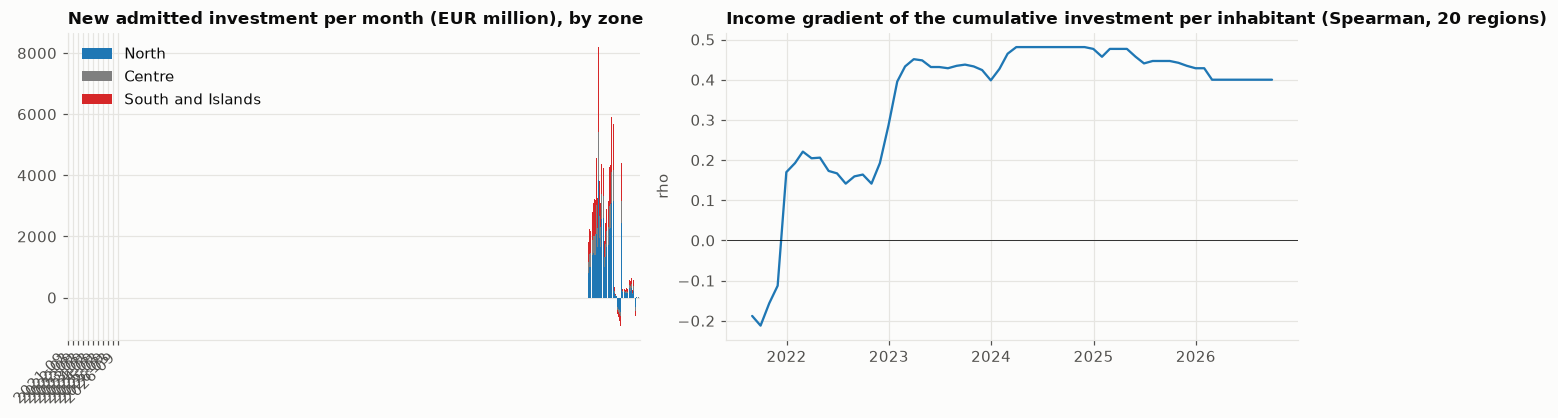

In [10]:
zw = bres["b39_superbonus_zone_windows"]; gw = bres["b40_superbonus_window_gradient"]; pb = bres["b41_superbonus_gradient_placebo"]; gp = bres["b42_superbonus_gradient_path"].set_index("date").rho
mf = bres["b43_superbonus_monthly_flows"].set_index("date"); cm = bres["b44_superbonus_completion"].set_index("date"); nb = bres["b45_superbonus_basis_national"]; rb = bres["b46_superbonus_basis_regions"]; ck = bres["b47_superbonus_monthly_checks"].set_index("date")
print("checks: largest |regions - Italy| over the 62 months (EUR):", ck.filter(like="gap_").abs().max().round(0).to_dict(), "| months with a regional decrease of the cumulative completed investment:", int((ck.n_decreases > 0).sum()), "(ENEA revisions, the largest in May 2026)")
print("monthly report against the national snapshots transcribed from the annual reports (EUR million, completed works):"); display(nb.round(3))
print("annual regional table (works ended by 31 December, later extraction) against the monthly report of the same month end, by region:"); display(rb.round(3))
print("share of the window's new admitted investment by zone against the population share (ratio 1 = in proportion):"); display(zw.pivot(index="window", columns="zone", values="ratio_of_shares").reindex(zw.window.unique()).round(2))
print("flow of admitted investment by window, EUR million:", zw.groupby("window", sort=False).flow_meur.sum().round(0).to_dict())
print("pre-specified family: income gradient of the new works, 8 windows (Spearman over 20 regions, permutation p, BH q):"); display(gw[gw.basis.eq("admitted")].drop(columns="basis").round(3).reset_index(drop=True))
print("robustness, completed works:"); display(gw[gw.basis.eq("completed")].drop(columns="basis").round(3).reset_index(drop=True))
print("placebo (regional incomes shuffled, whole family rerun): share of shuffles with any discovery at q < 0.05, mean discoveries:", pb.round(3).to_dict("records")[0])
print("cumulative gradient (rho of investment per inhabitant against income) at selected month ends:", {str(k.date()): round(float(v), 2) for k, v in gp.loc[["2021-08-31", "2022-06-30", "2022-11-30", "2022-12-31", "2023-01-31", "2023-03-31", "2023-12-31", "2024-12-31", "2026-09-30"]].items()})
print("share of the admitted investment already completed, by zone:"); display(cm.round(3))
print("largest months of new admitted investment (EUR million):", mf.sum(axis=1).sort_values(ascending=False).head(4).round(0).to_dict(), "| by calendar year:", mf.sum(axis=1).groupby(mf.index.year).sum().round(0).to_dict())
zcol = {"North": "#1f77b4", "Centre": "#7f7f7f", "South and Islands": "#d62728"}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9)); mf.plot.bar(stacked=True, ax=ax[0], width=0.9, color=[zcol[c] for c in mf.columns]); ax[0].set_xticks(range(0, len(mf), 6)); ax[0].set_xticklabels([str(d.date())[:7] for d in mf.index[::6]], rotation=45, ha="right")
ax[0].set_title("New admitted investment per month (EUR million), by zone"); ax[0].set_xlabel("")
ax[1].plot(gp.index, gp.values, color="#1f77b4"); ax[1].axhline(0, color="k", lw=0.5); ax[1].set_title("Income gradient of the cumulative investment per inhabitant (Spearman, 20 regions)"); ax[1].set_ylabel("rho")
plt.tight_layout(); plt.show()


### Did the regions that used the Superbonus more change differently? The link to the regional outcomes of notebook 34
ENEA's investment for completed works per inhabitant (end-2023 snapshot, 20 regions; Trentino-Alto Adige sums its two NUTS2 regions) against the change of the notebook 34 outcomes between 2019 and 2023 (Eurostat NUTS2; rates in percentage points, income and output per hour and hours per inhabitant in log points x 100). **Pre-specified**: Spearman of the investment per inhabitant against the change of the employment rate 20-64, permutation p over regions. **Placebos**: the same outcome over 2015-2019, which the credit cannot have affected; the investment shuffled within the three zones; and the whole 12-test family (6 outcomes x 2 periods, BH) rerun on shuffled investments. Robustness (not a family): investment per euro of 2019 GDP, and the rank correlation beyond the 2021 income level and the 2015-19 change. Descriptive: the credit followed the housing stock, ownership and the ability to advance the cost.


In [11]:
ol = bres["b49_superbonus_outcome_link"]; orb = bres["b50_superbonus_outcome_robustness"]; opl = bres["b51_superbonus_outcome_placebo"].round(3).to_dict("records")[0]
print("pre-specified test and the 12-test family (rho over 20 regions, permutation p over regions and within zones, BH q); 'before' = 2015-19 placebo window:"); display(ol.round(3))
print("robustness for the primary outcome:"); display(orb.round(3))
print("placebo (investment shuffled across regions, family rerun):", opl)
print("regions with the most and the least investment per inhabitant: employment-rate change 2019-23 and 2015-19 (pp):"); oc = bres["b48_superbonus_outcome_changes"].set_index("region"); rr2 = rr[rr.snapshot.eq("2023-12-31")].set_index("region").per_inhabitant_eur
display(pd.DataFrame({"investment_eur_per_inhabitant": rr2, "employment_change_2019_23": oc["employment_rate_20_64|after"], "employment_change_2015_19": oc["employment_rate_20_64|before"]}).sort_values("investment_eur_per_inhabitant", ascending=False).iloc[[0, 1, 2, 3, -4, -3, -2, -1]].round(2))


pre-specified test and the 12-test family (rho over 20 regions, permutation p over regions and within zones, BH q); 'before' = 2015-19 placebo window:


,outcome,window,n,rho,p,p_within_zone,primary,q
0,gdp_pps_pc_eu27,after,20,0.208,0.375,0.257,False,0.643
1,gdp_pps_pc_eu27,before,20,0.008,0.974,0.972,False,0.998
2,gdp_per_hour_eur,after,20,0.325,0.166,0.179,False,0.433
3,gdp_per_hour_eur,before,20,-0.006,0.982,0.981,False,0.998
4,hours_per_inhabitant,after,20,-0.140,0.558,0.578,False,0.744
5,hours_per_inhabitant,before,20,-0.002,0.998,0.997,False,0.998
6,employment_rate_20_64,after,20,-0.311,0.181,0.206,True,0.433
7,employment_rate_20_64,before,20,0.370,0.111,0.112,False,0.433
8,employment_rate_20_64_female,after,20,0.211,0.366,0.325,False,0.643
9,employment_rate_20_64_female,before,20,0.457,0.044,0.062,False,0.266


robustness for the primary outcome:


,variant,n,rho,p
0,per euro of GDP,20,0.302,0.191
1,beyond 2021 GDP per inhabitant,20,-0.079,0.741
2,beyond income and the 2015-19 change,20,0.081,0.732


placebo (investment shuffled across regions, family rerun): {'n_shuffle': 600, 'share_with_discovery': 0.038, 'mean_discoveries': 0.053}
regions with the most and the least investment per inhabitant: employment-rate change 2019-23 and 2015-19 (pp):


,investment_eur_per_inhabitant,employment_change_2019_23,employment_change_2015_19
region,,,
Valle d'Aosta,3519.19,3.80,2.70
Trentino-Alto Adige,2461.87,1.02,2.57
Basilicata,2331.38,4.30,1.70
Abruzzo,2313.15,3.40,4.00
Puglia,1238.37,4.40,3.30
Sicilia,1137.47,4.00,1.30
Liguria,1109.24,4.50,1.00
Campania,1069.58,3.20,2.10


### Dating the policy changes of the winter 2022-23 against the monthly reports
`data/external/superbonus_policy_dates.csv` lists the dated rule changes (each date from two independent institutions, or labelled `partly verified`): the Aiuti-quater decree of 18 November 2022 (DL 176/2022, GU n. 270) with its 25 November cut-off for the CILA, the budget law of 29 December 2022, the stop to credit transfer and invoice discount of 16-17 February 2023 (DL 11/2023), the MEF note of 30 March 2023 on the single-family extension and the conversion law of 11 April 2023. ENEA counts the investment when the works are transmitted, so a rule on the start of works can show up only with a lag: the timing can rule an explanation out, not date its effect. **Pre-specified**: two events (the first full month after the cut-off, December 2022, and after the end of transfers, March 2023) x two measures (the income gradient of the month's admitted investment, and the national monthly flow): contrast of the six months from the cut against the five before, ranked among every possible cut from January 2022 to March 2026 (a rough yardstick: months are serially dependent and other rules sit among them), BH over the four. The gradient by building type shows what it is made of.


dated rule changes (evidence label; every verified date has at least two sources):

,date,date_type,title,instrument,evidence
0,2022-09-30,threshold,Single-family 110% condition date: 30% of the ...,DL 50/2022 as converted (condition restated in...,verified
1,2022-11-18,enacted,Aiuti-quater decree published,"DL 176/2022, GU n. 270 of 2022-11-18, in force...",verified
2,2022-11-25,cutoff,110% kept for 2023 if the CILA was filed by th...,DL 176/2022 art. 9 c. 2,verified
3,2022-12-15,announced,Minister announces the CILAS extension to 2022...,Statement of the Minister of Economy at a pres...,partly verified
4,2022-12-29,enacted,Budget law 2023 published,"L. 197/2022, GU n. 303 of 2022-12-29 (S.O. n. ...",verified
5,2023-01-13,enacted,Aiuti-quater converted into law,"L. 6/2023 of 2023-01-13, GU n. 13 of 2023-01-17",partly verified
6,2023-02-16,enacted,Stop to credit transfer and invoice discount p...,"DL 11/2023, GU n. 40 of 2023-02-16, in force 2...",verified
7,2023-03-27,committee_approved,Chamber Finance Committee approves the amendme...,"A.C. 889 (conversion of DL 11/2023), VI Commis...",verified
8,2023-03-30,announced,MEF note: amendments to DL 11/2023 extend the ...,MEF note of 2023-03-30 on two amendments appro...,partly verified
9,2023-03-30,vote,Chamber confidence vote on the conversion bill...,"Chamber floor, A.C. 889",partly verified


pre-specified event tests (D = mean after six months minus mean before five; rank among every cut, BH q):


,event,measure,cut_month_end,D,n_cuts,rank,p_rank,max_abs_D,cut_of_max,q
0,"CILA cut-off, 25 Nov 2022",gradient (rho),2022-12-31,0.415,50,12,0.240,0.738,2024-05-31,0.767
1,"CILA cut-off, 25 Nov 2022",flow (log ratio of means),2022-12-31,-0.372,43,22,0.512,4.157,2026-03-31,0.767
2,"end of transfer / invoice discount, 17 Feb 2023",gradient (rho),2023-03-31,-0.150,50,34,0.680,0.738,2024-05-31,0.767
3,"end of transfer / invoice discount, 17 Feb 2023",flow (log ratio of means),2023-03-31,-0.232,43,33,0.767,4.157,2026-03-31,0.767


onset: {'gradient_onset': '2022-11-30', 'single_family_flow_base_meur': 1606.0, 'single_family_halved': '2022-11-30'}
exploratory proxy for starts (no project-level CILA dates are published): new buildings entering the ENEA report per month, by type:


date,2022-07-31,2022-08-31,2022-09-30,2022-10-31,2022-11-30,2022-12-31,2023-01-31,2023-02-28,2023-03-31,2023-04-30,2023-05-31,2023-06-30
all,24827.0,19956.0,63284.0,19628.0,12131.0,20490.0,12863.0,12655.0,18850.0,3587.0,4476.0,5316.0
condominiums,3151.0,2003.0,2517.0,2714.0,2859.0,4676.0,3160.0,3613.0,4363.0,2020.0,2795.0,3440.0
single-family,14782.0,12472.0,44388.0,12246.0,6397.0,11194.0,6483.0,6033.0,10302.0,1057.0,1225.0,1355.0
independent units,6894.0,5481.0,16378.0,4668.0,2875.0,4620.0,3220.0,3009.0,4185.0,510.0,456.0,521.0


... (2 outputs left out)

single-family monthly flow after the extension was approved (27 Mar 2023, deadline 31 Mar -> 30 Sep), EUR million: {Timestamp('2023-02-28 00:00:00'): 702.0, Timestamp('2023-03-31 00:00:00'): 1184.0, Timestamp('2023-04-30 00:00:00'): 126.0, Timestamp('2023-05-31 00:00:00'): 153.0, Timestamp('2023-06-30 00:00:00'): 159.0, Timestamp('2023-07-31 00:00:00'): 110.0, Timestamp('2023-08-31 00:00:00'): 69.0, Timestamp('2023-09-30 00:00:00'): 80.0, Timestamp('2023-10-31 00:00:00'): 103.0}
income gradient of the month's admitted investment per inhabitant (Spearman over 20 regions) by building type:


date,2022-07-31,2022-08-31,2022-09-30,2022-10-31,2022-11-30,2022-12-31,2023-01-31,2023-02-28,2023-03-31,2023-04-30,2023-05-31,2023-06-30
all,0.22,0.09,-0.28,0.32,0.55,0.71,0.78,0.80,0.66,0.32,0.29,0.54
condominiums,0.41,0.45,0.60,0.30,0.52,0.57,0.66,0.75,0.63,0.30,0.29,0.51
single-family,-0.31,-0.32,-0.66,-0.19,0.20,0.41,0.64,0.57,0.50,-0.28,-0.21,0.17
independent units,0.17,0.24,0.21,0.39,0.47,0.58,0.78,0.77,0.56,0.11,0.06,0.29


monthly admitted investment by building type, EUR million:


date,2022-07-31,2022-08-31,2022-09-30,2022-10-31,2022-11-30,2022-12-31,2023-01-31,2023-02-28,2023-03-31,2023-04-30,2023-05-31,2023-06-30
all,4541.0,3267.0,8194.0,3812.0,3087.0,4381.0,2746.0,3283.0,4228.0,1862.0,2444.0,2891.0
condominiums,2117.0,1273.0,1506.0,1941.0,2051.0,2640.0,1691.0,2309.0,2661.0,1694.0,2248.0,2681.0
single-family,1728.0,1437.0,5097.0,1415.0,761.0,1296.0,756.0,702.0,1184.0,126.0,153.0,159.0
independent units,697.0,556.0,1591.0,457.0,276.0,446.0,298.0,273.0,383.0,42.0,43.0,51.0


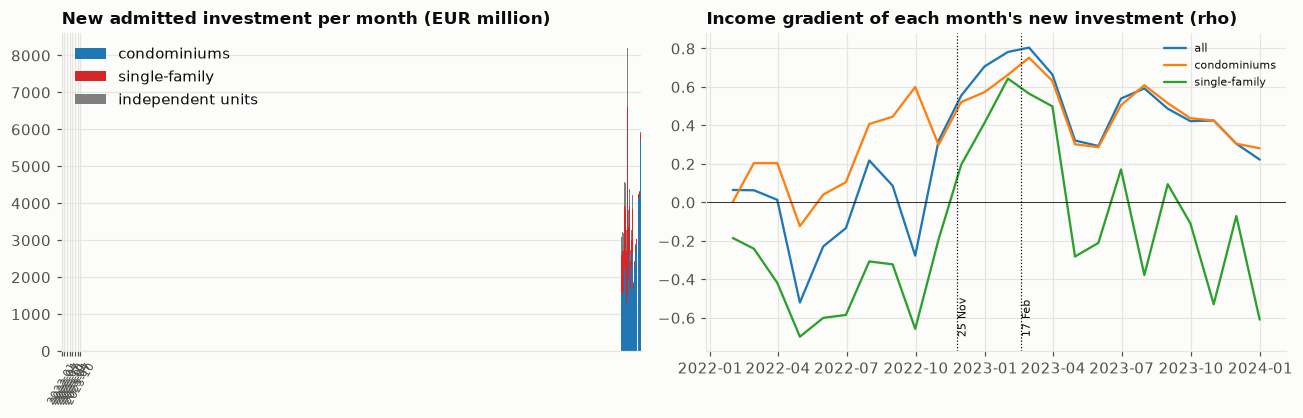

In [12]:
pdts = bres["b52_superbonus_policy_dates"]; tp = bres["b53_superbonus_monthly_path"].set_index("date"); te = bres["b54_superbonus_event_tests"]; on = bres["b55_superbonus_onset"].round(0).to_dict("records")[0]
print("dated rule changes (evidence label; every verified date has at least two sources):"); display(pdts[["date", "date_type", "title", "instrument", "evidence"]])
print("pre-specified event tests (D = mean after six months minus mean before five; rank among every cut, BH q):"); display(te.round(3))
print("onset:", on)
nbld = bres["b56_superbonus_new_buildings"].set_index("date"); nbt = bres["b57_superbonus_new_buildings_tests"]
print("exploratory proxy for starts (no project-level CILA dates are published): new buildings entering the ENEA report per month, by type:"); display(nbld.loc["2022-07-31":"2023-06-30"].round(0).T)
print("log-ratio contrasts of the new-building counts (six months from the cut against five before), rank among every cut month; not part of the pre-specified family:"); display(nbt.round(3))
print("single-family monthly flow after the extension was approved (27 Mar 2023, deadline 31 Mar -> 30 Sep), EUR million:", tp["single-family|flow_meur"].loc["2023-02-28":"2023-10-31"].round(0).to_dict())
g = tp[[c for c in tp.columns if c.endswith("|rho")]].loc["2022-01-31":"2023-12-31"]; g.columns = [c.split("|")[0] for c in g.columns]
print("income gradient of the month's admitted investment per inhabitant (Spearman over 20 regions) by building type:"); display(g.loc["2022-07-31":"2023-06-30"].round(2).T)
fl = tp[[c for c in tp.columns if c.endswith("|flow_meur")]].loc["2022-01-31":"2023-12-31"]; fl.columns = [c.split("|")[0] for c in fl.columns]
print("monthly admitted investment by building type, EUR million:"); display(fl.loc["2022-07-31":"2023-06-30"].round(0).T)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9)); fl[["condominiums", "single-family", "independent units"]].plot.bar(stacked=True, ax=ax[0], width=0.9, color=["#1f77b4", "#d62728", "#7f7f7f"]); ax[0].set_xticks(range(0, len(fl), 3)); ax[0].set_xticklabels([str(d.date())[:7] for d in fl.index[::3]], rotation=60, fontsize=7); ax[0].set_title("New admitted investment per month (EUR million)"); ax[0].set_xlabel("")
for k in ["all", "condominiums", "single-family"]: ax[1].plot(g.index, g[k], label=k)
for d, lab in [("2022-11-25", "25 Nov"), ("2023-02-17", "17 Feb")]: ax[1].axvline(pd.Timestamp(d), color="k", ls=":", lw=0.8); ax[1].text(pd.Timestamp(d), -0.7, lab, fontsize=7, rotation=90, va="bottom")
ax[1].axhline(0, color="k", lw=0.5); ax[1].legend(fontsize=7); ax[1].set_title("Income gradient of each month's new investment (rho)")
plt.tight_layout(); plt.show()


### Re-basing the lower bound on the monthly national series
The lower bound above uses the December snapshots transcribed from the annual reports. The monthly reports (Italy row at each December month end) are later extractions: the same cumulative, with late transmissions in. Re-basing moves credits between years and leaves the three-year total where it was when the last snapshot is the same.


In [13]:
print("flows from the monthly reports (Italy row, December month ends), EUR:"); display(bres["b58_superbonus_rebased_flows"].round(3))
print("lower bound of the capital-transfer overrun on the two bases:"); display(bres["b59_superbonus_rebased_bound"].round(3))


flows from the monthly reports (Italy row, December month ends), EUR:


,budget_year,investments_admitted_eur,investments_completed_eur,deductions_accrued_eur,credit_rate
0,2021,1.620435e+10,1.118142e+10,1.229956e+10,1.10
1,2022,4.628938e+10,3.544926e+10,3.899419e+10,1.10
2,2023,4.018795e+10,4.441992e+10,4.843843e+10,1.09


lower bound of the capital-transfer overrun on the two bases:


,budget_year,credits_annual_meur,credits_monthly_meur,share_annual,share_monthly,share_investment_annual,share_investment_monthly,credits_ratio
0,2021,11724.785,12299.557,0.189,0.198,0.172,0.180,1.049
1,2022,37995.191,38994.186,0.611,0.627,0.556,0.570,1.026
2,2023,50012.165,48438.427,0.553,0.535,0.507,0.491,0.969
3,2021-23,99732.140,99732.170,0.465,0.465,0.424,0.424,1.000


## Takeaways (resources-and-uses tables of the budget-law dossiers, 2016-2026; net borrowing, first year unless stated; exploratory and descriptive)
- **Between 2016 and 2024 about half of each manovra was financed by deficit.** The coverage ratio (resources over uses) of the bill is 0.49-0.65 in 2016-2020 and 2023-2024 (2016 0.49, 2017 0.65, 2018 0.59, 2019 0.50, 2020 0.49, 2023 0.50, 2024 0.52), so 35% to 51% of the uses were not covered inside the law; 2021 (0.20, the pandemic budget) and 2022 (0.37, rebuilt from the measure lines) are the exceptions. 2025 (0.74) and 2026 (0.96) are the most covered. Summed over the three-year horizon the ratio runs from 0.30 (2022) to 0.80 (2023), 0.61 for 2025 and 0.79 for 2026: the coverage of the two latest laws is concentrated in the first year (0.74 against 0.61; 0.96 against 0.79), while for 2017, 2023 and 2024 the three-year ratio is the higher one.
- **Size.** The planned deficit effect of the bill is between 0.39% of GDP (2025) and 1.34% (2021); outside 2021 the largest is 2019 (1.21%, Conte I). The 2019 figures are those of the initial text: the dossier's table for the final texts has a balance of -11.5 billion on net borrowing in 2019 against -21.8 billion initially, so these series describe what each government *proposed*, and the approved law can be much smaller. Adding the decree-law that goes with the bill (2020, 2024) moves the ratio from 0.49 to 0.57 and from 0.52 to 0.57.
- **What covers the manovra.** Lower spending is the larger source in 2016 (0.29 against 0.20 from higher revenue), 2017 (0.35 against 0.30) and above all 2025 (0.50 against 0.24); higher revenue dominates in 2018 (0.40 against 0.18) and 2026 (0.43 against 0.30). "Lower spending" is a planned reduction against the baseline, not a cut from the previous year's spending. 2019 has totals only (a ratio, no composition). 2022 has no published gross split: its uses (36.8 billion) and resources (13.5 billion) are rebuilt from the measure lines of the Senate budget service's note, giving a ratio of 0.37, higher revenue 0.22 of the uses and lower spending 0.15 (deficit effect -23.3 billion, 1.16% of GDP); this sums every measure line as a use or a resource, so it is comparable with the dossiers' tables but is not the government's own table.
- **The pandemic decrees are a different object.** The 2020 decrees have uses of 115.4 billion and resources of 10.2 billion (coverage 0.09, a deficit effect of 6.3% of GDP); DL 41/2021 covers 0.03 (1.7% of GDP).
- **No link between the planned deficit effect and the realised deficit or debt can be shown.** 0 of 6 tests of the pre-specified family survive false-discovery control (smallest q 0.186) and all six correlations are negative (-0.14 to -0.64), the opposite of the expected sign. The strongest are against the change in debt/GDP: the planned deficit effect, rho -0.64 (p 0.052, q 0.186), and the deficit-financed share, -0.61 (p 0.062, q 0.186); without 2020-21 -0.70 (q 0.19) and -0.78 (p 0.028, q 0.17); with the pandemic decrees added to 2020 and 2021 the six correlations lie between -0.45 and -0.02. The year-shuffle null gives 0.087 discoveries per shuffle and a discovery in 6% of 300 shuffles (nominal about 5%), and the lead placebo (the manovra against the previous year's outcomes) finds nothing either (rho 0.05 to 0.38, smallest q 0.72). Before the 2022 gross split was rebuilt, the 2022 law was missing from the three tests on the deficit-financed share (n 9) and the smallest q was 0.365: the conclusion, 0 of 6, is the same.
- **Why this is not a surprise.** The planned effect of a bill (0.4-1.3% of GDP) is small next to what moves the deficit and the debt: nominal growth lowered debt/GDP by 14.5, 11.7 and 9.3 points in 2021-2023 (the ratio fell by 8.6, 7.7 and 4.4 points in total) while the planned effects were the largest of the period (1.34%, 1.16%, 0.99%), and the ratio rose in 2024-2025 (+0.3, +2.4 points) when they were small (0.71%, 0.39%); interest adds 3.1 to 3.8 points every year and the stock-flow residual +1.7 and +2.6 points in 2024 and 2025. The negative signs reflect the timing of the growth shock and not an effect of the manovra: with about ten years the correlation does not separate them.
- **The deficit targets were missed in both directions.** The outturn was above the target in 2016-2018 (by 0.2, 0.2 and 0.6 points of GDP), below it in 2019 (-0.9 against the initial 2.4, -0.54 against the revised 2.04), far above in 2020 (+7.2), and above again in 2021-2023 (+1.9, +2.5, +2.6) before coming in below in 2024 (-0.9) and 2025 (-0.2). The outturns are the latest Eurostat vintage, so they include later revisions that the targets could not know about.
- **The size and the financing of the manovra do not line up with the miss.** The planned deficit effect against the deficit surprise: rho 0.29 (p 0.41, q 0.41) and the deficit-financed share 0.49 (p 0.16, q 0.32), both positive as expected but not significant; without 2020-21 they are 0.07 and 0.35 (q 0.87 and 0.79); against the revised target 0.32 and 0.49 (q 0.37 and 0.32). The year-shuffle null gives a discovery in 5% of shuffles. The change that the target implied (target minus last year's outturn) went with the realised change in the deficit: rho 0.75 (p 0.014, same sign in 8 of 10 years), 0.62 without 2020-21 (p 0.107, same sign in 6 of 8): the targets carried information about direction, which says nothing about the manovra itself.
- **What the misses were made of.** Measured as euro levels in % of the outturn GDP, with the effect of the GDP forecast error kept apart, the 2020 miss (+7.2) is 3.3 points of revenue shortfall and 3.9 of primary-expenditure overrun (interest -0.2, GDP denominator +0.2). In 2021, 2022 and 2023 (+1.9, +2.5, +2.6) primary expenditure ran 3.5, 3.7 and 3.8 points above the plan, partly offset by revenue above the plan (shortfall -1.7, -2.2, -0.7), with interest 1.35 points above plan in 2022. The two years below target had revenue above plan (-2.1 in 2024, -1.0 in 2025) and spending above plan too (+1.5, +0.9). The denominator effect is small (at most 0.31 points in absolute value) and moves with the nominal GDP error as it must (rho -0.90, p 0.001). Nominal GDP grew faster than forecast in 2021-2023 (+3.6, +2.3, +2.4 points) and, outside 2020-21, the miss was larger when nominal growth beat the forecast (rho 0.74, p 0.043, n 8): inflation lifted revenue, but spending went further above plan. By category (next section), the 2021-2023 overruns are almost entirely **capital transfers (ESA D.9)**: +3.4, +3.1 and +4.2 points of GDP (89%, 61% and 118% of the miss of total expenditure; the next largest category is +0.3 in 2021 and 2023 and interest, +1.35, in 2022). This is consistent with the Eurostat decision of early 2023 under which Istat records the Superbonus and bonus facciate credits as payable tax credits, i.e. capital expenditure at the time of the works (reported by AGI on 1 March 2023, which also gives the revised deficits: 2021 9.0% against 7.2% before, 2022 8.0% against the 5.6% target), but D.9 also holds other capital transfers (investment grants among them), so the amount due to the building credits alone is not isolated here; a lower bound from the Superbonus alone is given in the next bullet. The 2020 miss splits between capital transfers (+1.5), social payments (+1.3) and subsidies (+0.6).
- **The Superbonus alone accounts for at least about half of the capital-transfer overrun of 2021-23.** ENEA's bulletins give Superbonus credits accrued of 11.7, 38.0 and 50.0 billion euro in 2021, 2022 and 2023 (investments for completed works 10.7, 34.5 and 45.8 billion; credit rate 1.10, 1.10, 1.09; 2021 is the cumulative since July 2020), against capital-transfer overruns of 62.0, 62.2 and 90.5 billion: 19%, 61% and 55% of the overrun, 46% over the three years (99.7 against 214.7 billion; 0.64, 1.90 and 2.34% of GDP against 3.37, 3.11 and 4.22). With the investment instead of the credit the shares are 17%, 56% and 51%. This is a **lower bound**: ENEA has the Superbonus only, so the facade bonus, the ordinary ecobonus and sismabonus and the other building bonuses are in the remainder (50.3, 24.2 and 40.4 billion), and so are other capital transfers; the overrun is measured against the plan, which may already hold part of the credits, and the snapshots are by transmission date of the asseverations, so late transmissions understate a year and overstate the next (the 2021 share is the lowest also because the Eurostat treatment books the credits when the works are done and 2021 is early in the programme). It makes the building-credit explanation of the overruns quantitatively plausible (more than half of the 2022 and 2023 overruns come from one measure), without separating it from the other bonuses.
- **Istat's own figures put the Superbonus at about three quarters of the overrun, and with the facade bonus over four fifths.** The Superbonus effect on net borrowing of 0.9, 2.8 and 3.9% of GDP in 2021-23 is 16.5, 56.0 and 83.5 billion euro with the outturn GDP: 27%, 90% and 92% of the capital-transfer overrun of each year, 73% over the three years (156.0 against 214.7 billion); adding the facade bonus (about 23 billion, 2020-22, no annual split) gives 83% (179 against 215 billion). The ENEA credits are 64% of Istat's figure over the three years (71%, 68%, 60%): the gap is probably the super sismabonus (outside the SuperEcobonus reports) and the accounting rules for when and at what value a credit is booked, which this note cannot separate. What is left (about 36 billion euro, 17%) is other building bonuses, other capital transfers and the difference between the plan and the accounts. Source caveat: the Istat figures are quoted from a Camera dossier, not from the note itself; an earlier MEF estimate (DEF 2023) put the new treatment's effect at 0.2, 1.8 and 2.6 points of GDP in 2020-22 for the Superbonus and the facade bonus together, a different vintage.

- **Three primary sources agree, and the year 2021 is where the building credits explain least.** The Bank of Italy's memorandum of 22 April 2024 puts the credits matured at about 1%, almost 3% and 3.7% of GDP in 2021-23 and almost 8% together, against Istat's 0.9, 2.8 and 3.9 (total 7.6): the same magnitudes from an official body, with the 2023 gap being Istat's later revision (3.7 preliminary of 5 April, 3.9 in the note of 26 April). Istat's hearing of March 2023 (the first booking in full) has the spending for the Superbonus and facade bonus together at about 2.0, 35.8 and 50.4 billion euro in 2020-22 (a chart without labels, +-0.5 billion), i.e. 58% of the 2021 overrun and 81% of 2022; later revisions raised 2022 (Superbonus alone 56.0 billion in the April 2024 vintage), so the vintages differ and are alternatives. Across the sources the building credits are 19% to 58% of the 2021 overrun, 61% to 96% of 2022 and 55% to 92% of 2023: **2021 is the year where at least 40% of the capital-transfer overrun (26 billion with Istat's March 2023 figure) is something else**. Istat's hearing also has the spending for tax credits in favour of all firms (about 18.8 billion in 2021 and 33.3 billion in 2022, 10.3 in 2020) and, in its Tavola 1, their composition by type: see the next bullet. The Istat note of 26 April 2024 itself (obtained from the Senate and read: 0.03, 0.9, 2.8, 3.9% of GDP, over 150 billion euro, over 175 with the facade bonus) confirms the Camera dossier's figures; it gives no split of the facade bonus by year.
- **Firms' investment tax credits close most of the gap in 2021 and all of it in 2022.** Istat's Tavola 1 (hearing of 15 March 2023, page 23) splits the firms' tax credits by type; Istat does not give the ESA category of each, so the grouping is a judgment, in two widths: *core* = Transizione 4.0 and Investimenti Mezzogiorno (credits tied to the firm's investment, investment grants), *wide* = core + R&D, deferred-tax-asset conversion and the vehicle bonus. With the Istat March 2023 figures, the capital-transfer overrun of 2021 (62.0 billion) minus the Superbonus and facade spending (35.8) leaves 26.2 billion; the core credits are 7.0 billion (24.0% + 13.4% of 18.8) and the wide ones 13.6, leaving 19.2 (31% of the overrun) or 12.6 billion (20%) unexplained. In 2022 the overrun minus the building bonuses is 11.8 billion and the core credits alone are 12.4 (29.2% + 8.0% of 33.3): the overrun is fully explained (remainder -0.6, or -4.1 with the wide set). The subsidy-type credits (Covid, freight, audiovisual, fund-perduto, other, and the energy credits of 2022) are a cross-check on the category: 5.2 billion in 2021 against a subsidies overrun of 5.1 billion, and 17.4 billion in 2022 (energy credits 14.4) against 11.9. What is left in 2021 (13-19 billion, 20-31% of the overrun) is not identified: candidates are capital transfers outside tax credits (the PNRR and other grants, guarantees called) and the difference between the plan and the accounts. Limits: the vintages differ (March 2023 for the credits, the latest Eurostat vintage for the overrun), the chart totals are read to +-0.5 billion, the category grouping is a judgment, and the overrun is against the plan, which may already hold part of these credits.
- **The unexplained part of 2021 sits in other capital transfers (D.99), not in investment grants (D.92).** Eurostat splits Italy's capital transfers: investment grants (D.92, where the building bonuses and the firms' investment credits are recorded) rise from 14.4 billion euro in 2019 to 58.8 in 2021 (+44.4), which the building bonuses plus the firms' investment credits (42.8 to 49.4 billion) account for; other capital transfers (D.99, cash grants) rise from 5.4 to 33.1 (+27.7), against 25.0 in 2020 (+19.6), the pandemic years. The part of the 2021 overrun left over by the credits (12.6 to 19.2 billion) is therefore inside the D.99 increase, which fits cash grants decided after the budget plan was written (the Sostegni decrees of 2021: the technical report of DL 73/2021 books the grants to firms as capital spending in net borrowing, which we saw in its prospetto) but cannot be tied to them item by item here. In 2022 the D.99 is back to 12.0 billion (+6.6) while D.92 is 75.5 billion above 2019, 9 to 13 billion more than the credits above, plausibly PNRR investment grants. These categories are Eurostat's (gov_10a_main, % of GDP times GDP), not a match to Istat's credit table.
- **The Sostegni grants cover the 2021 D.99 increase, but authorized is not booked.** The technical reports and the law as converted (parliamentary dossiers of DL 41/2021 and DL 73/2021, Normattiva, `data/external/covid_grants_2021.csv`) authorize 11,150 million euro of contributi a fondo perduto in DL 41 (art. 1) and, in DL 73 (art. 1 as converted), 5,873 (automatic, down from 8,000 in the initial text), 3,400 (alternative) and 4,000 + 452.1 (worst-hit operators, of which 3,150 are unused DL 41 resources and only 850 new): 21.7 billion of distinct money. Other capital transfers (D.99) in 2021 are 33.1 billion: the 2019 level (5.4) plus 21.7 leaves 6.0 billion of other items. The Agenzia delle Entrate paid 5.21 billion of the automatic tranche (1.81 million beneficiaries) by 22 June 2021 against 5.87 authorized (89%); at that rate the grants would be 19.3 billion and the D.99 left over 8.4. The grants (19.3 to 21.7 billion) therefore cover the 12.6 to 19.2 billion that the building bonuses and firms' investment credits leave unexplained, in the order of magnitude, in both readings; the booked amounts are not known. This does not prove the classification: the technical reports book DL 41's grants as current spending, and the Government's table for DL 73 books them as capital spending in net borrowing; the D.99 increase and the 2020 jump of the same kind (+19.6 billion) point to Istat booking them as other capital transfers. Eurostat's April 2020 draft note on the COVID-19 measures discusses subsidies on production (D.39) and other capital transfers (D.99) for business support without settling it for lump-sum grants.
- **Istat's accounts by receiving sector settle the 2021 question and replace the judgment grouping.** In the October 2022 edition the households' investment grants were 2.3 billion euro in 2021; the March 2023 edition, which books the Superbonus and the facade bonus as payable credits in full, has 37.9 (+35.6) and moves net lending of 2021 by -32.3 billion and of 2020 by -2.7 (exactly Istat's published revisions); the corporations' other capital transfers (D.99), where the cash grants of the pandemic decrees sit, were already 32.6 billion in 2021 in the October 2022 edition (so the grants were classified there from the start, not reclassified). In the latest edition (October 2026) the 2021 rise over 2019 of D.92 + D.99 is 73.2 billion: **36.9 (50%) households' investment grants** (the building bonuses), **7.6 (10%) corporations' investment grants** (the firms' investment credits), **27.0 (37%) corporations' other capital transfers** (the cash grants) and 1.8 other. The hearing's chart of the Superbonus and facade spending (2.0, 35.8 and 50.4 billion) matches the households' grants above 2019 of the March 2023 edition within 0.8 billion (2.0, 36.6, 50.1). Taking the households' rise above 2019 as Superbonus plus facade bonus, Istat's Superbonus effect of the note of 26 April 2024 leaves an implied **facade bonus of 1.5 (2020), 20.3 (2021), -0.1 (2022) and 0.6 (2023) billion**, 21.7 for 2020-22 (22.3 with 2023), which agrees with the 'about 23 billion' of the Camera dossier and answers the open question of the annual split (an assumption, with +-1 billion from the one-decimal Superbonus incidence). What this changes: the corporations' investment-grant rise of 7.6 billion in 2021 is close to the core credits of the grouping above (7.0) and the wide set (13.6) overstated it; in 2022 it is 19.4 against 12.4 (core) and 15.9 (wide), so more than the credits of Istat's table (probably the PNRR and other grants to firms); and the corporations' D.99 rise of 27.0 billion in 2021 exceeds the authorized Sostegni grants (21.7) by 5.3 billion, which the firms' tax credits of Istat's table (Covid credits 2.5 billion) and other transfers can cover but this cannot show. The 2021 remainder is therefore no longer open: it is the cash grants to firms, in Istat's own classification.
- **Most of the 2021 deficit surprise is the March 2023 reclassification.** In the edition of October 2022 (before the Superbonus and the facade bonus were booked in full) the 2021 deficit was 128.9 billion euro, 7.01% of the latest GDP, against a target of 7.0: a surprise of +0.01 points. In the March 2023 edition it is 161.2 billion (8.77%, +1.77 points), in the latest 164.0 (8.92%, +1.92): the +1.9 points of the surprise table above are 1.77 points of accounting treatment and about 0.15 points of other revisions. For 2022 the first edition already includes the reclassification (+2.08 points in March 2023, +2.47 in the latest), so it cannot be cleaned in the same way; the 2022 plan (5.6) was also written under the cash treatment. This links to the cross-country ranking of notebook 41: Italy's 2021-23 overrun is largely an accounting overrun that other countries, which did not book payable credits this way, do not share, so the placement is a placement of the accounting regime as much as of the forecasts (the early-estimate check of notebook 41 shows the same: Italy's 2021 deficit revised up by 1.7 points of GDP after the early estimate, the others by 0.2 at most).
- **With the first release of each year the misses look different, and most of the large revisions are 2021.** Re-running the decomposition of the deficit surprise with Istat's first edition of each year (2019-2025; the first edition containing the year, the March or April of the next one) instead of the latest: the 2021 surprise is -0.07 points (first release) against +1.92 (latest), a revision of +1.99 almost all in primary expenditure (+2.64, the building credits booked as capital transfers) partly offset by revenue (-0.66); 2022 +2.08 against +2.47 (first edition March 2023, already reclassified; revision +0.39: primary expenditure +0.70, revenue -0.24), 2023 +2.48 against +2.60, 2020 +7.18 against +7.17, 2019 -0.77 against -0.92, 2024 -0.88 against -0.91, 2025 -0.20 against -0.22. So the first-release outturns of 2022 and 2023 already show the overrun (+2.1 and +2.5 points, primary expenditure +3.0 and +3.7), and the 2021 overrun that stood out in the latest data was not visible at the first release; the correlations between the manovra and the surprise of the second family are computed on the latest vintage and the 2021 point is the one that moves most. The deficits are in % of the latest nominal GDP (the GDP of each edition is not in the account), so only the numerator changes and the denominator effect is the same in both vintages.
- **The quarterly account shows when the credits were booked.** Other capital expenditure (D.92 + D.99) runs at 3.8 to 4.0 billion euro a quarter in 2019, rises with the pandemic grants (14.7 and 16.5 in the last two quarters of 2020, 28.1 in the second quarter of 2021 when the Sostegni grants were paid) and, with the credits, to 19.7-32.7 in 2022; **the fourth quarter of 2023 is 51.4 billion, 40% of the year (127.5)**, plausibly the last quarter before the rate fell to 70% for 2024 (Istat's note of 26 April 2024: 90% for 2023, 70% for 2024, 65% for 2025, with wide derogations in 2023), and **2024-Q1 falls to 7.6 billion**. The March 2023 booking moved the earlier quarters in an almost even way: net lending of 2021 by -9.1, -8.6, -6.8 and -7.8 billion over the four quarters (other capital expenditure +9.9, +9.5, +9.1, +8.8), of 2022 by -10.7, -15.0 and -21.4 billion in the first three quarters (the edition of January 2023 had only three quarters of 2022), so the credits accrue with the works through the year and the later years carry more. Quarterly figures are the raw series; the sum of the four quarters of 2021 (92.7 billion) matches the annual D.92 + D.99 (91.9) within 1%.
- **The Superbonus went more to the richer regions, and the gap narrowed over time.** ENEA's investments for completed works by region (`data/external/enea_superbonus_regions.csv`, end 2023 and end 2025; SuperEcobonus only) give the North 53.9% of the end-2023 investment against 46.4% of the population (ratio 1.16; 1,851 euro per inhabitant), the Centre 18.2% against 19.9% (0.91; 1,454) and the South and Islands 27.9% against 33.7% (0.83; 1,319); by the end of 2025 the ratios are 1.15, 0.93 and 0.84 (2,283, 1,842 and 1,681 euro per inhabitant). Across the 20 regions the investment per inhabitant of the end-2023 snapshot goes with GDP per inhabitant (Spearman 0.51, permutation p 0.026; 0.43, p 0.063 at the end of 2025) and with the condominium share (0.45, p 0.049; 0.37, p 0.10 at the end of 2025). The highest per inhabitant are Valle d'Aosta (3,519 euro), Trentino-Alto Adige (2,462), Basilicata (2,331) and Abruzzo (2,313), the lowest Campania (1,070), Liguria (1,109), Sicilia (1,137) and Puglia (1,238): the relation is moderate with clear exceptions in both directions (Basilicata and Abruzzo high, Lazio, Liguria and Campania low). Twenty regions, one pre-specified test (end-2023 snapshot, per inhabitant) and robustness checks that are not a family; GDP per inhabitant is workplace based and not the income of the households that used the credit; the investments follow the housing stock, ownership and the ability to advance the cost, so this is a description of who benefited, not an explanation. Istat's regional accounts (esploradati, households' disposable income by region) stop at the income account: they have no capital transfers received by region, so the regional split of the households' investment grants cannot be taken from them.
- **The income gradient of the Superbonus appeared in 2023, not before.** The ENEA monthly reports (62 month ends, `data/external/enea_superbonus_monthly.csv`) split the new admitted investment by window. The South's ratio of its share of the new works to its population share is 1.02 up to August 2021, 0.90 in September-December 2021, 1.03 in the first half of 2022 and 0.87 in the second, then **0.69 in the first half of 2023**, 0.84, 0.72 in 2024 and 0.94 in 2025-26 (the North 0.96, 1.09, 0.98, 1.10, 1.28, 1.16, 1.25, 1.04). In the pre-specified family of 8 windows (Spearman across the 20 regions of the admitted investment per inhabitant against GDP per inhabitant) the correlation is -0.17, 0.16, 0.00 and 0.31 up to the end of 2022 (none significant), then 0.74 in the first half of 2023 (q 0.003), 0.42 in the second half (q 0.18), 0.59 in 2024 (q 0.031) and -0.17 in 2025-26: **2 of 8 windows survive false-discovery control** (the completed-works version agrees: 0.68, q 0.013, and 0.58, q 0.041), and the placebo that shuffles the regional incomes gives a discovery in 5.2% of 600 shuffles (mean 0.11 windows). The cumulative gradient goes from -0.19 in August 2021 to 0.19 in November 2022, 0.29 in December, 0.40 in January 2023 and 0.45 in March 2023, then stays at 0.40-0.48 (0.40 in December 2023, 0.48 in December 2024, 0.40 in September 2026): it was built in the winter of 2022-23, the months of the 2023 rate cut and of the stop to credit transfers (known policy changes that this note does not date or test). New admitted investment peaks at 8.2 billion euro in September 2022 (46.3 billion in 2022, 40.2 in 2023, 16.4 in 2024, 4.9 in 2025); the South also completes more slowly (87% of the admitted investment completed at the end of 2023 against 90% in the North; 97.6% against 98.8% in September 2026). Limits: 20 regions per window, one family and a shuffled-income placebo, the SuperEcobonus only, flows by transmission date (late transmissions move works between windows and ENEA's own revisions give a fall of 602 million in May 2026, 3,051 buildings), and GDP per inhabitant is workplace based; this is who used the credit when, not why. Two basis notes: the annual report's regional table (works ended by 31 December, later extraction) is 0.75 to 1.05 times the monthly report of the same month end by region (Valle d'Aosta lowest, Molise highest) with the same ranking (Spearman 0.99), so the end-2023 test above is not sensitive to the basis; the monthly national totals match the transcribed snapshots at the bulletin basis (December 2023, March 2025) and are 5% and 3% above the annual-report figures of December 2021 and 2022 (not re-based in the lower bound above).
- **Istat's account and the Eurostat figures used here agree.** Putting Istat's latest edition in % of the project's nominal GDP and comparing with Eurostat's % of GDP for Italy over 2005-2024: net lending, compensation of employees, intermediate consumption, interest, subsidies and capital transfers (D.92 + D.99) and also total expenditure and total revenue differ by at most 0.04 to 0.05 points of GDP in any year (the rounding of Eurostat's one decimal is 0.05; Eurostat release of 21 October 2026). With the July 2026 release total expenditure differed by up to 0.19 (2021) and total revenue by up to 0.13 (2018): that gap was the vintage, not a definition difference. So the Eurostat numbers used in notebooks 38 and 41 are the same accounts as the Istat ones, and the Istat editions add the revision history, the receiving sector and the quarters.
- **Limits.** About ten years, so only a rank correlation of about 0.65 or more can be told from zero: a moderate true link would not be detected. The outcomes are the year-on-year change in the outturn (latest Eurostat vintage), not the manovra's effect; the cycle, interest and one-off items move them too. The deficit target is the one stated when the law was proposed (for 2019 also the revised one); targets for 2016-2022 come from the draft budgetary plans (two tables of each agree) and for 2023-2026 from the dossiers' programmatic row. Figures are ex-ante estimates from the government's technical reports for the bill as first presented (2022: rebuilt from the measure lines of the budget service's note, not a published table), one country and no placebo countries (a placebo ranking would need the same tables for other euro-area countries). Descriptive associations only.
- **No link between the regional use of the Superbonus and the change of the regional outcomes.** The pre-specified test (investment per inhabitant against the change of the employment rate 20-64, 2019-23, 20 regions) gives rho -0.31 (permutation p 0.18, within zones 0.21); in the 2015-19 placebo window the same correlation is +0.37 (p 0.11), so the regions that used the credit more were not the ones whose employment was falling behind. Of the 12 tests (6 outcomes x 2 periods) none survives BH (smallest q 0.27: unemployment change 2019-23, rho +0.49, p 0.029; female employment 2015-19, rho +0.46, p 0.044); the shuffled family gives a discovery in 3.8% of 600 shuffles (mean 0.05). Per euro of 2019 GDP rho is 0.30 (p 0.19) for the primary outcome; beyond the 2021 income level it is -0.08 and beyond income and the 2015-19 change 0.08. A negative result with 20 regions: a gap of the size seen in Italy's recovery would need a larger sample or the project-level data; this does not say the credit had no regional effect. Descriptive.
- **The timing cannot attribute the 2023 income gradient to the winter rules.** Dates (two sources each: Normattiva or the Gazzetta, the Camera dossier, ANCE, Assolombarda): DL 176/2022 published 18 November 2022 with the CILA cut-off at 25 November, budget law 29 December, DL 11/2023 published 16 February and in force 17 February 2023, conversion 11 April; the 30 March 2023 MEF note is `partly verified`. The monthly gradient of the new admitted investment (rho over 20 regions) is -0.28 in September 2022, 0.32 in October (before the decree), 0.55 in November, 0.71, 0.78, 0.80 in December-February, then 0.66, 0.32, 0.29, 0.54: it begins to rise a month before the first rule and is carried by the single-family houses, whose flow falls from 5.1 billion euro in September 2022 (the 30 September condition date, rho -0.66) to 1.4, 0.8 and 1.3 billion in October-December; the condominiums have a positive gradient throughout. Pre-specified contrasts (2 events x 2 measures): none stands out among the possible cut months (the December 2022 gradient contrast +0.42 ranks 12 of 50, p 0.24; BH q 0.77 for all four). Reads: the winter rules cannot be shown to have created the gradient, and the data cannot date their effect either (flows by transmission lag the start of works). Descriptive.
- **Re-basing the lower bound on the monthly series moves credits between years, not the total.** Credits accrued of 12.3, 39.0 and 48.4 billion euro in 2021-23 against 11.7, 38.0 and 50.0 on the annual-report basis (ratios 1.05, 1.03, 0.97), so the share of the capital-transfer overrun is 19.8%, 62.7% and 53.5% (19%, 61%, 55% before); over the three years 99.7 billion and 46.5% on both bases, because the December 2023 cumulative is the same. Late transmissions raise the earlier years and lower the last one, as the basis note said.
